# Assignment 2
#### Casey Elizabeth Gilbert

In [3]:
# import a bunch of stuff
import networkx as nx
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as path_effects
from matplotlib import rc
import time
import random
import math
from collections import Counter

## Question 1

#### Question 1a

In [35]:
def grow_barabasi_albert_net(N, m, seed=None, debug=False):
    """
    This function creates a scale-free network using barabasi-albert model.

    It loops through and adds the proper amount of nodes (specified as param).
    For each node, it connects via m links to existing nodes. 

    NOTES:
    Adds links with preferential attachment, the preferential attachment comes from choosing a random edge.
    So a node with twice as many edges is twice as likely to have an edge chosen.
    Because degree = edge count * 2, th probability for each node is then halved
    This is taken care of when we randomly select one of the edge's nodes.
    
    This doesn't allow self loops, and isn't exactly LCD, but it is computationally cleaner,
    and I think should create scale-free networks.

    @param N (int): The number of nodes
    @param m (int): Number of edges formed for each new node
    @param seed (int?): The seed for the network (optional)
    @param debug (bool): Whether or not you want print statements

    @return the scale-free network
    @return an array of degree sequences at N^x
    """

    # Create the graph
    degree_sequences = []
    simple_graph = nx.complete_graph(4)
    start_graph = nx.MultiGraph(simple_graph) # multilinks are allowed

    # Set our seed
    random.seed(seed)

    # Our time counter
    # Start with 4 because the network always starts with 4 nodes
    t = 4

    # get our order of magnitude so we know what to print
    o_of_m = int(math.log10(N))

    degree_sequences_vals = []
    if (o_of_m > 1):
        for i in range(2,o_of_m + 1):
            degree_sequences_vals.append(10**i)
    if debug: print(degree_sequences_vals)
    while t < N:
        t = t + 1

        # add node
        start_graph.add_node(t)

        # we don't want to accidentally select the new node's edge,
        # so we get the edge list ahead of time
        edge_list = list(start_graph.edges) 

        # Now add the m edges
        # Note that this doesn't allow self-links
        # But I don't think that's a requirement for BA; according to the book
        # BA leaves many mathematical details open
        for i in range(0,m):
            # get random edge
            chosen_edge = edge_list[random.randint(0,len(edge_list)-1)]
            if debug: print(f"chosen_edge: {chosen_edge}")

            #randomly choose one edge of that link
            chosen_node = chosen_edge[random.randint(0,1)]
            if debug: print(f"Chosen node: {chosen_node}")

            # attach the new edge 
            start_graph.add_edge(t, chosen_node)

        # we want the degree sequence of certain orders of magnitude
        if t in degree_sequences_vals:
            degree_seq = np.array(list(dict(start_graph.degree()).values()))
            degree_sequences.append(degree_seq)


    return start_graph, degree_sequences
    

In [28]:
def grow_barabasi_albert_net_later_option(N, m, seed=None, debug=False):
    """
    This function creates a scale-free network using barabasi-albert model.

    It loops through and adds the proper amount of nodes (specified as param).
    For each node, it connects via m links to existing nodes. 

    NOTES:
    This is a version I added because it preferentially adds links including the links 
    added as m. Which originally I did not do. And am still not clear if BA requires this. 
    But the below analysis was done with only using preferential attachement for nodes that
    are not new. 

    @param N (int): The number of nodes
    @param m (int): Number of edges formed for each new node
    @param seed (int?): The seed for the network (optional)
    @param debug (bool): Whether or not you want print statements

    @return the scale-free network
    @return an array of degree sequences at N^x
    """

    # Create the graph
    degree_sequences = []
    simple_graph = nx.complete_graph(4)
    start_graph = nx.MultiGraph(simple_graph) # multilinks are allowed

    # Set our seed
    random.seed(seed)

    # Our time counter
    # Start with 4 because the network always starts with 4 nodes
    t = 4
    edge_list = list(start_graph.edges) 

    # get our order of magnitude so we know what to print
    o_of_m = int(math.log10(N))

    degree_sequences_vals = []
    if (o_of_m > 1):
        for i in range(2,o_of_m + 1):
            degree_sequences_vals.append(10**i)
    if debug: print(degree_sequences_vals)
    while t < N:
        t = t + 1

        # add node
        start_graph.add_node(t)

        edge_list = list(start_graph.edges) 

        # Now add the m edges
        # Note that this doesn't allow self-links
        # But I don't think that's a requirement for BA; according to the book
        # BA leaves many mathematical details open
        for i in range(0,m):
            # get random edge
            chosen_edge = edge_list[random.randint(0,len(edge_list)-1)]
            if debug: print(f"chosen_edge: {chosen_edge}")

            #randomly choose one edge of that link
            chosen_node = chosen_edge[random.randint(0,1)]
            if debug: print(f"Chosen node: {chosen_node}")

            # attach the new edge 
            start_graph.add_edge(t, chosen_node)
            edge_list.append((t, chosen_node))

        # we want the degree sequence of certain orders of magnitude
        if t in degree_sequences_vals:
            degree_seq = np.array(list(dict(start_graph.degree()).values()))
            degree_sequences.append(degree_seq)


    return start_graph, degree_sequences

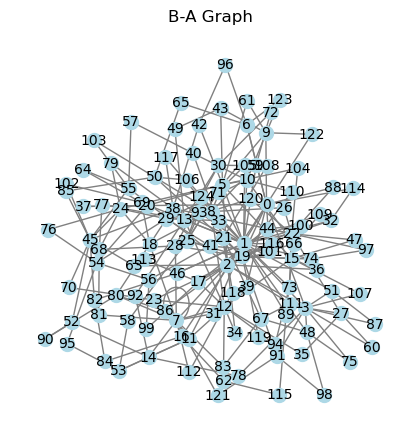

In [19]:
N = 10**4
m = 4
# Just test it with smaller numbers to see what's up
G, degree_dists = grow_barabasi_albert_net(124,2)

plt.figure(figsize=(4, 4))
nx.draw(G, with_labels=True, node_color='lightblue', edge_color='gray', node_size=100, font_size=10)
plt.title("B-A Graph")
plt.show()

In [36]:
N = 10**4
m = 4
# Just test it with smaller numbers to see what's up
G, degree_dists = grow_barabasi_albert_net(N,m)

In [21]:
degree_dists

[array([21, 17, 17, 41, 26, 24, 31,  6, 16, 12, 12,  6, 22, 12,  8, 13,  8,
        11, 15,  9,  7,  9, 13, 23,  6,  4,  7,  8,  6, 10,  5,  5,  8,  5,
         8, 10, 11,  6,  4,  6,  6,  6,  8,  6,  5,  4,  7,  6,  6,  8,  4,
         7,  5,  5,  4,  6,  5,  4,  4,  4,  6,  4,  4,  5,  4,  4,  5,  4,
         4,  5,  6,  4,  4,  5,  5,  5,  7,  6,  6,  6,  5,  4,  4,  4,  4,
         4,  5,  4,  4,  4,  4,  4,  5,  4,  4,  4,  4,  4,  4,  4]),
 array([ 44,  49,  61, 131,  85,  77, 116,  28,  62,  36,  25,  28,  85,
         35,  13,  37,  16,  38,  47,  31,  25,  44,  35,  73,  15,   9,
         44,  24,  22,  23,   7,   7,  32,  20,  31,  19,  30,  24,  10,
         18,  23,  13,  36,  21,   7,   7,  30,  18,  26,  30,  19,  20,
         13,  13,  20,  20,  19,  13,   8,  21,  19,   6,   7,   9,   6,
         15,  18,  15,  14,  22,  15,  14,  13,  11,  23,  16,  21,  17,
         24,  12,  14,   9,   6,   8,   6,  10,  14,   7,  12,  22,   8,
         17,   8,   9,   6,   8,  12,  

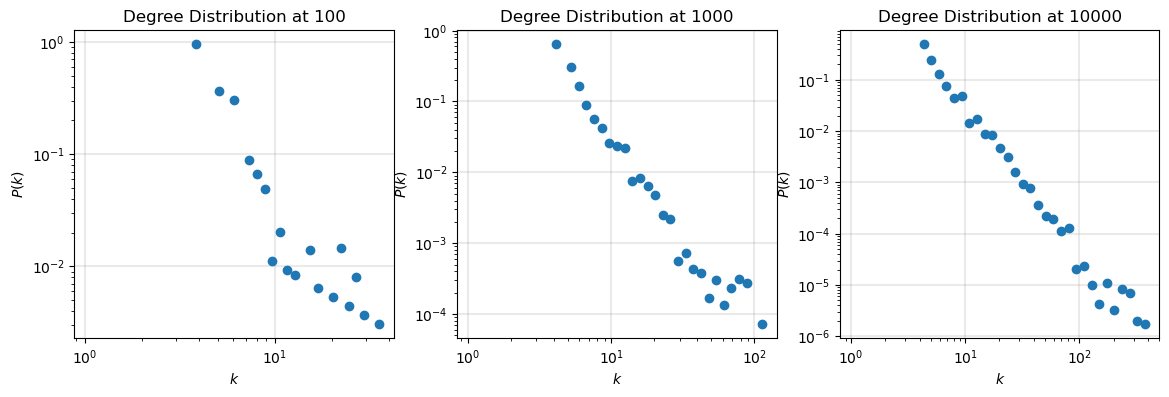

In [37]:
fig, ax = plt.subplots(1,len(degree_dists),figsize=(14,4),dpi=100)

for i in range(0, len(degree_dists)):
    # get nice binned distributions 
    deg_vals = degree_dists[i]
    deg_bins = np.logspace(0, np.log10(np.max(deg_vals)+1), num=40)
    probs, _ = np.histogram(deg_vals, bins=deg_bins, density=True)
    final_bins = deg_bins[1:] - np.diff(deg_bins)/2.0

    # plot that puppy
    ax[i].loglog(final_bins, probs, marker='o',lw=0)
    ax[i].set_xlabel(r"$k$", fontsize='medium')
    ax[i].set_ylabel(r"$P(k)$", fontsize='medium')
    ax[i].grid(linewidth=1.5, color='#999999', alpha=0.2, linestyle='-')
    ax[i].set_title(f'Degree Distribution at {10**(i+2)}', fontsize='large')

plt.show()

#### Question 1b

In [38]:
import powerlaw

for i,dist in enumerate(degree_dists):
    print(f"Dist: {10**(i+2)}")
    fit = powerlaw.Fit(dist)

    print(fit.power_law.alpha)
    print(fit.power_law.xmin)

Dist: 100
Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 19/19 [00:00<00:00, 1781.18it/s]
/Users/caseygilbert/anaconda3/envs/graph-tool/lib/python3.14/site-packages/powerlaw/distributions.py:183: UserWarning: discrete=False but data exclusively contains integer values. Consider using discrete=True.
  warnings.warn('discrete=False but data exclusively contains integer values. Consider using discrete=True.')


2.753243001852782
7.0
Dist: 1000
Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 38/38 [00:00<00:00, 2139.89it/s]
/Users/caseygilbert/anaconda3/envs/graph-tool/lib/python3.14/site-packages/powerlaw/distributions.py:183: UserWarning: discrete=False but data exclusively contains integer values. Consider using discrete=True.
  warnings.warn('discrete=False but data exclusively contains integer values. Consider using discrete=True.')


2.998116020908291
12.0
Dist: 10000
Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 92/92 [00:00<00:00, 1743.48it/s]

2.928863893711239
26.0



/Users/caseygilbert/anaconda3/envs/graph-tool/lib/python3.14/site-packages/powerlaw/distributions.py:183: UserWarning: discrete=False but data exclusively contains integer values. Consider using discrete=True.
  warnings.warn('discrete=False but data exclusively contains integer values. Consider using discrete=True.')


Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 19/19 [00:00<00:00, 1866.76it/s]
/Users/caseygilbert/anaconda3/envs/graph-tool/lib/python3.14/site-packages/powerlaw/distributions.py:183: UserWarning: discrete=False but data exclusively contains integer values. Consider using discrete=True.
  warnings.warn('discrete=False but data exclusively contains integer values. Consider using discrete=True.')
/var/folders/3n/4c447n7j2yv7hw5yxxvb35880000gn/T/ipykernel_15713/2072619701.py:18: UserWarning: Legend does not support handles for float64 instances.
A proxy artist may be used instead.
See: https://matplotlib.org/stable/users/explain/axes/legend_guide.html#controlling-the-legend-entries
  ax[i].legend([fit.power_law.alpha, fit.power_law.xmin], ['γ', 'k-min'], fontsize='small')


Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 38/38 [00:00<00:00, 1588.50it/s]
/Users/caseygilbert/anaconda3/envs/graph-tool/lib/python3.14/site-packages/powerlaw/distributions.py:183: UserWarning: discrete=False but data exclusively contains integer values. Consider using discrete=True.
  warnings.warn('discrete=False but data exclusively contains integer values. Consider using discrete=True.')
/var/folders/3n/4c447n7j2yv7hw5yxxvb35880000gn/T/ipykernel_15713/2072619701.py:18: UserWarning: Legend does not support handles for float64 instances.
A proxy artist may be used instead.
See: https://matplotlib.org/stable/users/explain/axes/legend_guide.html#controlling-the-legend-entries
  ax[i].legend([fit.power_law.alpha, fit.power_law.xmin], ['γ', 'k-min'], fontsize='small')


Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 92/92 [00:00<00:00, 1152.31it/s]
/Users/caseygilbert/anaconda3/envs/graph-tool/lib/python3.14/site-packages/powerlaw/distributions.py:183: UserWarning: discrete=False but data exclusively contains integer values. Consider using discrete=True.
  warnings.warn('discrete=False but data exclusively contains integer values. Consider using discrete=True.')
/var/folders/3n/4c447n7j2yv7hw5yxxvb35880000gn/T/ipykernel_15713/2072619701.py:18: UserWarning: Legend does not support handles for float64 instances.
A proxy artist may be used instead.
See: https://matplotlib.org/stable/users/explain/axes/legend_guide.html#controlling-the-legend-entries
  ax[i].legend([fit.power_law.alpha, fit.power_law.xmin], ['γ', 'k-min'], fontsize='small')


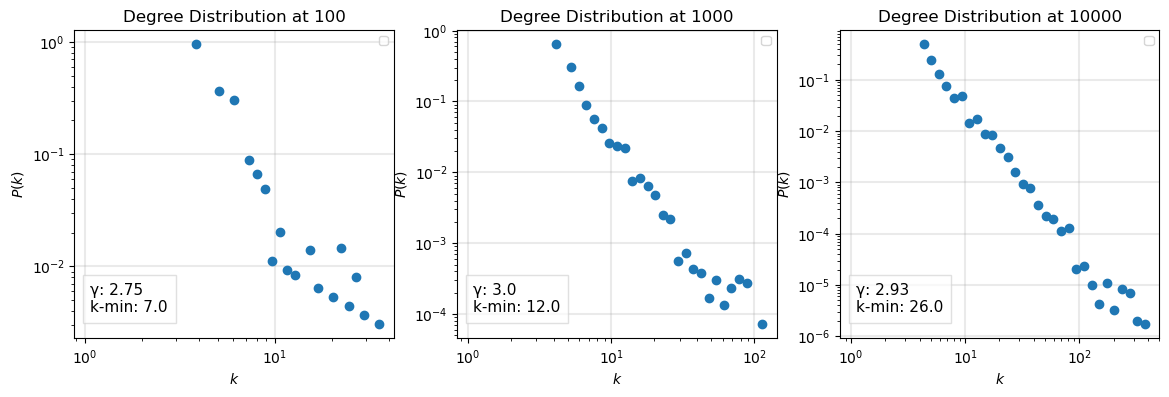

In [39]:
fig, ax = plt.subplots(1,len(degree_dists),figsize=(14,4),dpi=100)

for i,dist in enumerate(degree_dists):
    # fit the distribution
    fit = powerlaw.Fit(dist)

    # get nice binned distributions 
    deg_vals = degree_dists[i]
    deg_bins = np.logspace(0, np.log10(np.max(deg_vals)+1), num=40)
    probs, _ = np.histogram(deg_vals, bins=deg_bins, density=True)
    final_bins = deg_bins[1:] - np.diff(deg_bins)/2.0

    # plot that puppy
    ax[i].loglog(final_bins, probs, marker='o',lw=0)
    ax[i].set_xlabel(r"$k$", fontsize='medium')
    ax[i].set_ylabel(r"$P(k)$", fontsize='medium')
    ax[i].grid(linewidth=1.5, color='#999999', alpha=0.2, linestyle='-')
    ax[i].legend([fit.power_law.alpha, fit.power_law.xmin], ['γ', 'k-min'], fontsize='small')
    ax[i].set_title(f'Degree Distribution at {10**(i+2)}', fontsize='large')

    box_style = dict(facecolor='white', edgecolor='lightgrey', boxstyle='square,pad=0.5', alpha=0.7)
    fit_info = f"γ: {round(fit.power_law.alpha,2)} \nk-min: {round(fit.power_law.xmin,2)}"
    ax[i].text(0.05, 0.18, fit_info, verticalalignment='top', transform=ax[i].transAxes, fontsize=11, bbox=box_style)


plt.savefig('images/deg_dist_graphs.pdf', bbox_inches='tight')
plt.show()

In [10]:
for i,dist in enumerate(degree_dists):
    print(f"Dist {i}")
    dist = degree_dists[i]
    unique = list(set(dist))
    unique.sort()
    for k in unique: 
        num = 2*m * (m+1) 
        den = k*(k+1)*(k+2)
        print(f"deg: {k} and num: {num} and den: {den} and total: {num/den}")
    print("\n")

Dist 0
deg: 4 and num: 40 and den: 120 and total: 0.3333333333333333
deg: 5 and num: 40 and den: 210 and total: 0.19047619047619047
deg: 6 and num: 40 and den: 336 and total: 0.11904761904761904
deg: 7 and num: 40 and den: 504 and total: 0.07936507936507936
deg: 8 and num: 40 and den: 720 and total: 0.05555555555555555
deg: 9 and num: 40 and den: 990 and total: 0.04040404040404041
deg: 10 and num: 40 and den: 1320 and total: 0.030303030303030304
deg: 11 and num: 40 and den: 1716 and total: 0.023310023310023312
deg: 12 and num: 40 and den: 2184 and total: 0.018315018315018316
deg: 14 and num: 40 and den: 3360 and total: 0.011904761904761904
deg: 16 and num: 40 and den: 4896 and total: 0.008169934640522876
deg: 17 and num: 40 and den: 5814 and total: 0.0068799449604403165
deg: 22 and num: 40 and den: 12144 and total: 0.0032938076416337285
deg: 26 and num: 40 and den: 19656 and total: 0.002035002035002035
deg: 27 and num: 40 and den: 21924 and total: 0.0018244845831052727
deg: 31 and num:

### Question 1c

In [36]:
from tailestim import HillEstimator, KernelTypeEstimator, MomentsEstimator

def estimate_gamma(G):
    """
    This function estimates the gamma of a network's degree distribution using three different functions:
    - powerlaw estimate
    - hill estimate
    - moments estimate
    - Kernal-type estimate

    @param G (NetworkX network): The network you want to estimate

    @return a dict of the estimates, labeled "power", "hill", "moments", and "kernel"
    """

    gamma_estimates = dict()

    # Get the distribution 
    degree_seq = np.array(list(dict(G.degree()).values()))
    
    # powerlaw estimate
    fit = powerlaw.Fit(degree_seq)
    pwr_gamma = fit.power_law.alpha
    gamma_estimates["power"] = pwr_gamma

    # HillEstimator
    hill_estimator = HillEstimator()
    hill_estimator.fit(degree_seq)
    hill_result = hill_estimator.get_result()
    hill_gamma = hill_result.gamma_
    gamma_estimates["hill"] = hill_gamma

    # Moments Estimator
    moments_estimator = MomentsEstimator()
    moments_estimator.fit(degree_seq)
    moments_result = moments_estimator.get_result()
    moments_gamma = moments_result.gamma_
    gamma_estimates["moments"] = moments_gamma

    # Moments Estimator
    kernel_estimator = KernelTypeEstimator()
    kernel_estimator.fit(degree_seq)
    kernel_result = kernel_estimator.get_result()
    kernel_gamma = kernel_result.gamma_
    gamma_estimates["kernel"] = kernel_gamma

    return gamma_estimates



In [64]:
N = 10**4
m = 4

# networks
ba_networks = []

# our arrays of estimates
power_estimates = []
hill_estimates = []
moments_estimates = []
kernel_estimates = []

for i in range(0,100): 
    # Create the network and estimate it
    random_seed = random.randint(1,20000)
    temp_G, _ = grow_barabasi_albert_net(N,m,random_seed)
    ba_networks.append(temp_G)

    # Now estimates 
    estimates = estimate_gamma(temp_G)

    # add results to our arrays
    power_estimates.append(estimates["power"])
    hill_estimates.append(estimates["hill"])
    moments_estimates.append(estimates["moments"])
    kernel_estimates.append(estimates["kernel"])

print(power_estimates)
print(hill_estimates)
print(moments_estimates)
print(kernel_estimates)

Calculating best minimal value for power law fit
/Users/caseygilbert/anaconda3/envs/comp_methods_env/lib/python3.11/site-packages/powerlaw.py:699: RuntimeWarning: invalid value encountered in divide
  (CDF_diff**2) /
/Users/caseygilbert/anaconda3/envs/comp_methods_env/lib/python3.11/site-packages/tailestim/estimators/tail_methods.py:193: RuntimeWarning: invalid value encountered in divide
  | (np.abs(1.0 - (M1**2) / M2) < 1e-10)
/Users/caseygilbert/anaconda3/envs/comp_methods_env/lib/python3.11/site-packages/tailestim/estimators/tail_methods.py:194: RuntimeWarning: invalid value encountered in divide
  | (np.abs(1.0 - (M1 * M2) / M3) < 1e-10)
/Users/caseygilbert/anaconda3/envs/comp_methods_env/lib/python3.11/site-packages/tailestim/estimators/tail_methods.py:907: RuntimeWarning: invalid value encountered in divide
  xi_arr = gamma_pos - 1.0 + q2 / q1
/Users/caseygilbert/anaconda3/envs/comp_methods_env/lib/python3.11/site-packages/tailestim/estimators/tail_methods.py:976: RuntimeWarning

[np.float64(3.022884305298096), np.float64(3.0017509066266608), np.float64(3.1114192690239886), np.float64(3.1142637363991885), np.float64(3.0449710502758864), np.float64(3.020247323418742), np.float64(3.0460177417292145), np.float64(3.031289854501576), np.float64(3.0000442717607285), np.float64(3.096360627402655), np.float64(3.057041794022711), np.float64(3.0599537871717097), np.float64(3.0782402095866046), np.float64(3.107847697889699), np.float64(3.0607835860560137), np.float64(3.066704790715748), np.float64(3.0570229664735806), np.float64(3.036146467433602), np.float64(3.0095139421857424), np.float64(3.069517923610184), np.float64(3.038500911519243), np.float64(3.0454698798757307), np.float64(3.0070114649007893), np.float64(3.0370382110059495), np.float64(3.0201961685562377), np.float64(3.0772523533958123), np.float64(3.0138067432832365), np.float64(2.997200677271952), np.float64(3.052801021692208), np.float64(3.110914633331388), np.float64(3.07806924047789), np.float64(3.196738498

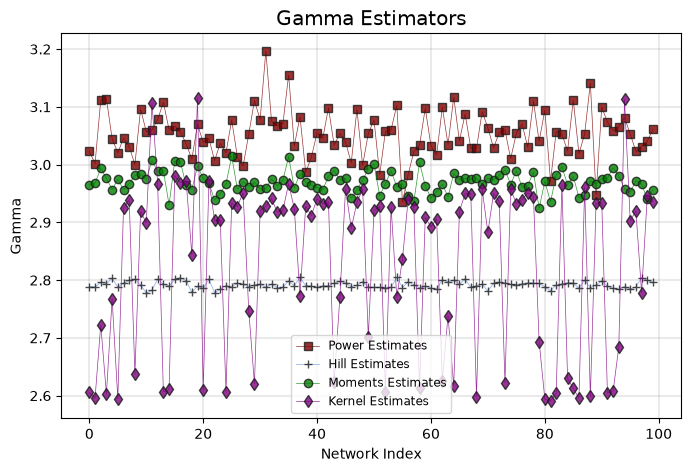

In [65]:
# Now graph it
fig, ax = plt.subplots(1,1,figsize=(8,5),dpi=100)
plt.subplots_adjust(wspace=0.3)

#ax.plot(power_estimates, 'o', color='maroon', label='Power Estimates', alpha=0.8, mec='.1')
ax.plot(power_estimates, label='Power Estimates', color='maroon', linestyle="-", marker='s', linewidth=0.5, alpha=0.8, mec='.1')
ax.plot(hill_estimates, '+', color='cornflowerblue', linestyle="-", label='Hill Estimates', alpha=0.8, mec='.1', linewidth=0.5)
ax.plot(moments_estimates, 'o', color='green', linestyle="-", label='Moments Estimates', alpha=0.8, mec='.1', linewidth=0.5)
ax.plot(kernel_estimates, 'd', color='purple', linestyle="-", label='Kernel Estimates', alpha=0.8, mec='.1', linewidth=0.5)

ax.set_xlabel(r"Network Index", fontsize='medium')
ax.set_ylabel(r"Gamma", fontsize='medium')
ax.legend(fontsize='small')
ax.grid(linewidth=1.5, color='#999999', alpha=0.2, linestyle='-')
ax.set_title('Gamma Estimators', fontsize='x-large')

plt.savefig('images/gamma_estimators.png', dpi=425, bbox_inches='tight')


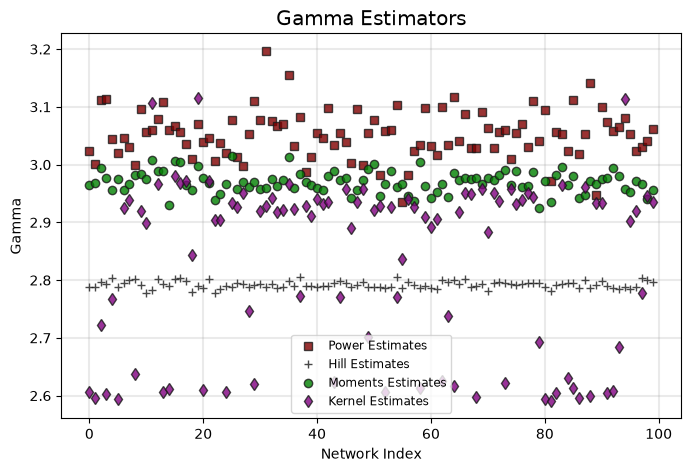

In [66]:
# Now graph it
fig, ax = plt.subplots(1,1,figsize=(8,5),dpi=100)
plt.subplots_adjust(wspace=0.3)

ax.plot(power_estimates, 's', label='Power Estimates', color='maroon', alpha=0.8, mec='.1')
ax.plot(hill_estimates, '+', color='cornflowerblue', label='Hill Estimates', alpha=0.8, mec='.1')
ax.plot(moments_estimates, 'o', color='green', label='Moments Estimates', alpha=0.8, mec='.1')
ax.plot(kernel_estimates, 'd', color='purple', label='Kernel Estimates', alpha=0.8, mec='.1')

ax.set_xlabel(r"Network Index", fontsize='medium')
ax.set_ylabel(r"Gamma", fontsize='medium')
ax.legend(fontsize='small')
ax.grid(linewidth=1.5, color='#999999', alpha=0.2, linestyle='-')
ax.set_title('Gamma Estimators', fontsize='x-large')

plt.savefig('images/gamma_estimators_no-line.png', dpi=425, bbox_inches='tight')


In [75]:
print(max(degree_seq))
print(min(degree_seq))

474
4


In [83]:
log_likelihoods = []
p_values = []
for network in ba_networks:
    # Get the distribution 
    degree_seq = np.array(list(dict(network.degree()).values()))

    # powerlaw estimate
    fit = powerlaw.Fit(degree_seq, xmin=4, discrete=True)
    R, p = fit.distribution_compare('power_law', 'lognormal')
    log_likelihoods.append(R)
    p_values.append(p)

/Users/caseygilbert/anaconda3/envs/comp_methods_env/lib/python3.11/site-packages/powerlaw.py:699: RuntimeWarning: invalid value encountered in divide
  (CDF_diff**2) /


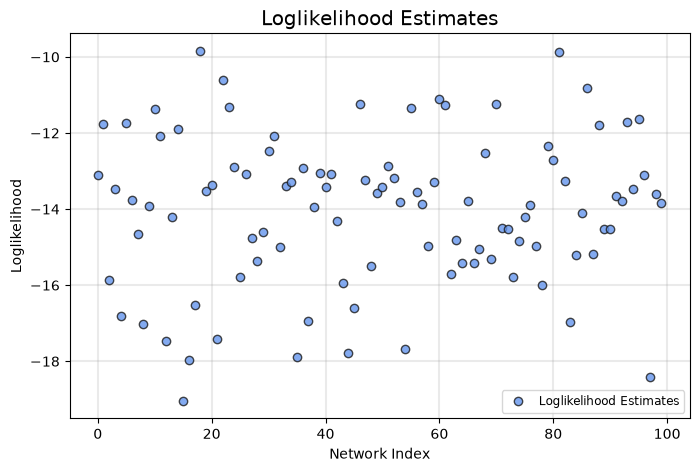

In [81]:
# Now graph it
fig, ax = plt.subplots(1,1,figsize=(8,5),dpi=100)
plt.subplots_adjust(wspace=0.3)

ax.plot(log_likelihoods, 'o', label='Loglikelihood Estimates', color='cornflowerblue', alpha=0.8, mec='.1')


ax.set_xlabel(r"Network Index", fontsize='medium')
ax.set_ylabel(r"Loglikelihood", fontsize='medium')
ax.legend(fontsize='small')
ax.grid(linewidth=1.5, color='#999999', alpha=0.2, linestyle='-')
ax.set_title('Loglikelihood Estimates', fontsize='x-large')

plt.savefig('images/log_likelihood_estimates.png', dpi=425, bbox_inches='tight')

## Question 2

#### Question 2a

6809
7680


/var/folders/3n/4c447n7j2yv7hw5yxxvb35880000gn/T/ipykernel_19106/3769131536.py:6: DeprecationWarning: The default value for `spmatrix` is changing to `False` in v1.20.
             That means the default return type will be a sparse array.
             Unless you use * instead of @, ** for matrix power, or you depend
             on 2D shapes from e.g. `A.sum(axis=0)` it may not matter to you.
             See the spmatrix to sparray migration guide for details.
             https://docs.scipy.org/doc/scipy/reference/sparse.migration_to_sparray.html
             
  matrix = mmread("data/ia-reality/ia-reality.mtx")


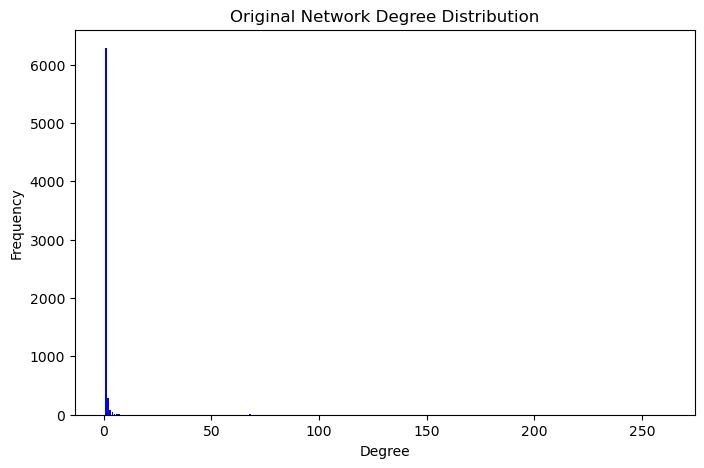

In [86]:
from scipy.io import mmread
import networkx as nx
import matplotlib.pyplot as plt

# Read in data
matrix = mmread("data/ia-reality/ia-reality.mtx")
mit_call_network = nx.Graph(matrix)

print(mit_call_network.number_of_nodes())
print(mit_call_network.number_of_edges())

hist = nx.degree_histogram(mit_call_network)
plt.figure(figsize=(8, 5))
plt.bar(range(len(hist)), hist, width=0.8, color="blue")

plt.title("Original Network Degree Distribution")
plt.xlabel("Degree")
plt.ylabel("Frequency")
plt.show()

In [87]:
communities = nx.community.louvain_communities(mit_call_network, seed=67)

nx_node_dict = {
    node: community_id 
    for community_id, community_nodes in enumerate(communities) 
    for node in community_nodes
}

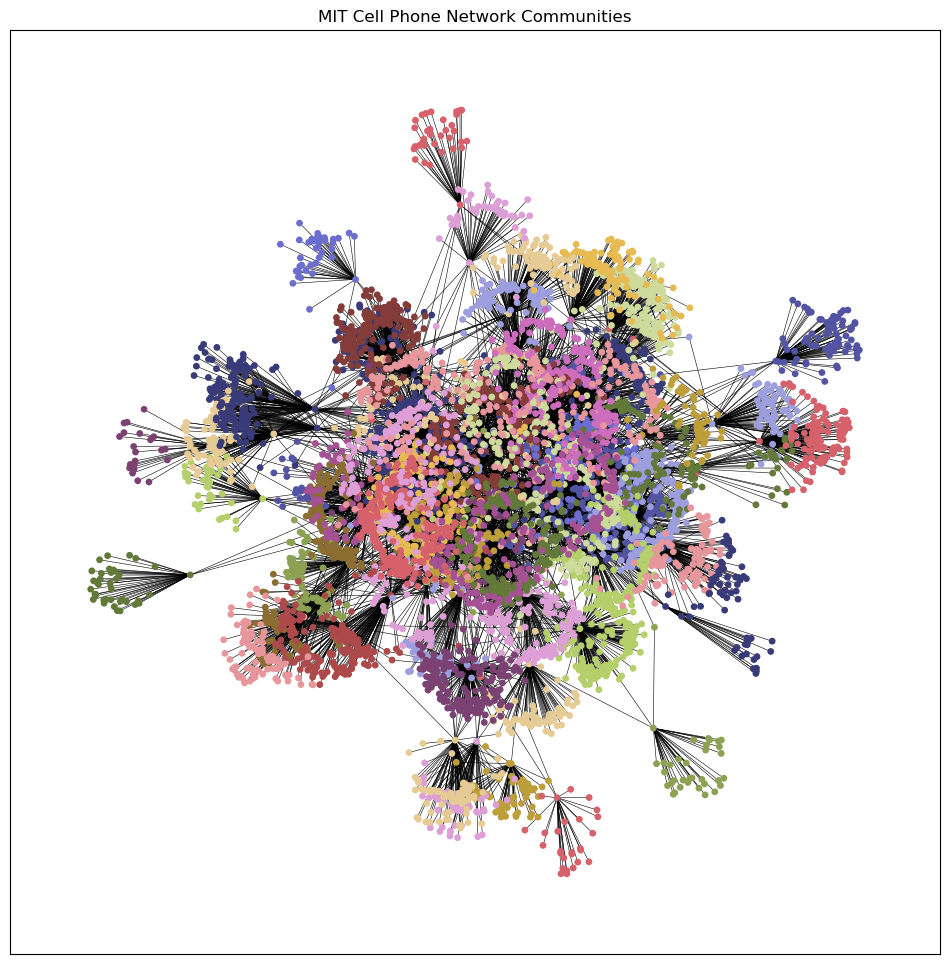

In [7]:
import numpy as np
pos = nx.spring_layout(mit_call_network)
colors_sns = plt.cm.tab20b(np.linspace(0,1,len(np.unique(list(communities)))))
colors_nodes = [colors_sns[nx_node_dict[node]] for node in mit_call_network.nodes()]

fig, ax = plt.subplots(1,1,figsize=(12,12),dpi=100)

nx.draw_networkx(mit_call_network, pos=pos, node_color=colors_nodes, with_labels=False, ax=ax, node_size=15,width=0.4,)
plt.title("MIT Cell Phone Network Communities")

plt.savefig("images/cellphone_communities.png")

plt.show()

In [8]:
# Get the modularity 
modularity = nx.community.quality.modularity(mit_call_network, communities)
print(f"Modularity: {modularity}")

# Get the number of communities
community_number = len(communities)
print(f"Community count: {community_number}")

# Node dictionary
print(nx_node_dict)

Modularity: 0.8729945458306206
Community count: 43
{0: 0, 3: 0, 16: 0, 89: 0, 90: 0, 93: 0, 94: 0, 95: 0, 96: 0, 97: 0, 98: 0, 100: 0, 101: 0, 103: 0, 104: 0, 105: 0, 106: 0, 107: 0, 108: 0, 110: 0, 111: 0, 112: 0, 114: 0, 116: 0, 117: 0, 118: 0, 119: 0, 120: 0, 121: 0, 122: 0, 123: 0, 124: 0, 125: 0, 126: 0, 127: 0, 128: 0, 129: 0, 130: 0, 131: 0, 132: 0, 133: 0, 134: 0, 135: 0, 136: 0, 137: 0, 138: 0, 139: 0, 141: 0, 143: 0, 144: 0, 145: 0, 146: 0, 147: 0, 148: 0, 149: 0, 150: 0, 151: 0, 152: 0, 153: 0, 154: 0, 155: 0, 156: 0, 159: 0, 161: 0, 162: 0, 164: 0, 165: 0, 166: 0, 167: 0, 168: 0, 169: 0, 170: 0, 171: 0, 172: 0, 173: 0, 174: 0, 175: 0, 176: 0, 177: 0, 178: 0, 179: 0, 180: 0, 181: 0, 182: 0, 183: 0, 184: 0, 185: 0, 190: 0, 191: 0, 558: 0, 559: 0, 560: 0, 561: 0, 562: 0, 563: 0, 566: 0, 567: 0, 568: 0, 570: 0, 571: 0, 572: 0, 573: 0, 574: 0, 575: 0, 576: 0, 577: 0, 578: 0, 579: 0, 580: 0, 581: 0, 583: 0, 584: 0, 585: 0, 586: 0, 587: 0, 588: 0, 589: 0, 590: 0, 591: 0, 592: 0, 5

In [9]:
import graph_tool.all as gt

/var/folders/3n/4c447n7j2yv7hw5yxxvb35880000gn/T/ipykernel_45856/4006474886.py:3: DeprecationWarning: The default value for `spmatrix` is changing to `False` in v1.20.
             That means the default return type will be a sparse array.
             Unless you use * instead of @, ** for matrix power, or you depend
             on 2D shapes from e.g. `A.sum(axis=0)` it may not matter to you.
             See the spmatrix to sparray migration guide for details.
             https://docs.scipy.org/doc/scipy/reference/sparse.migration_to_sparray.html
             
  matrix = mmread("data/ia-reality/ia-reality.mtx")


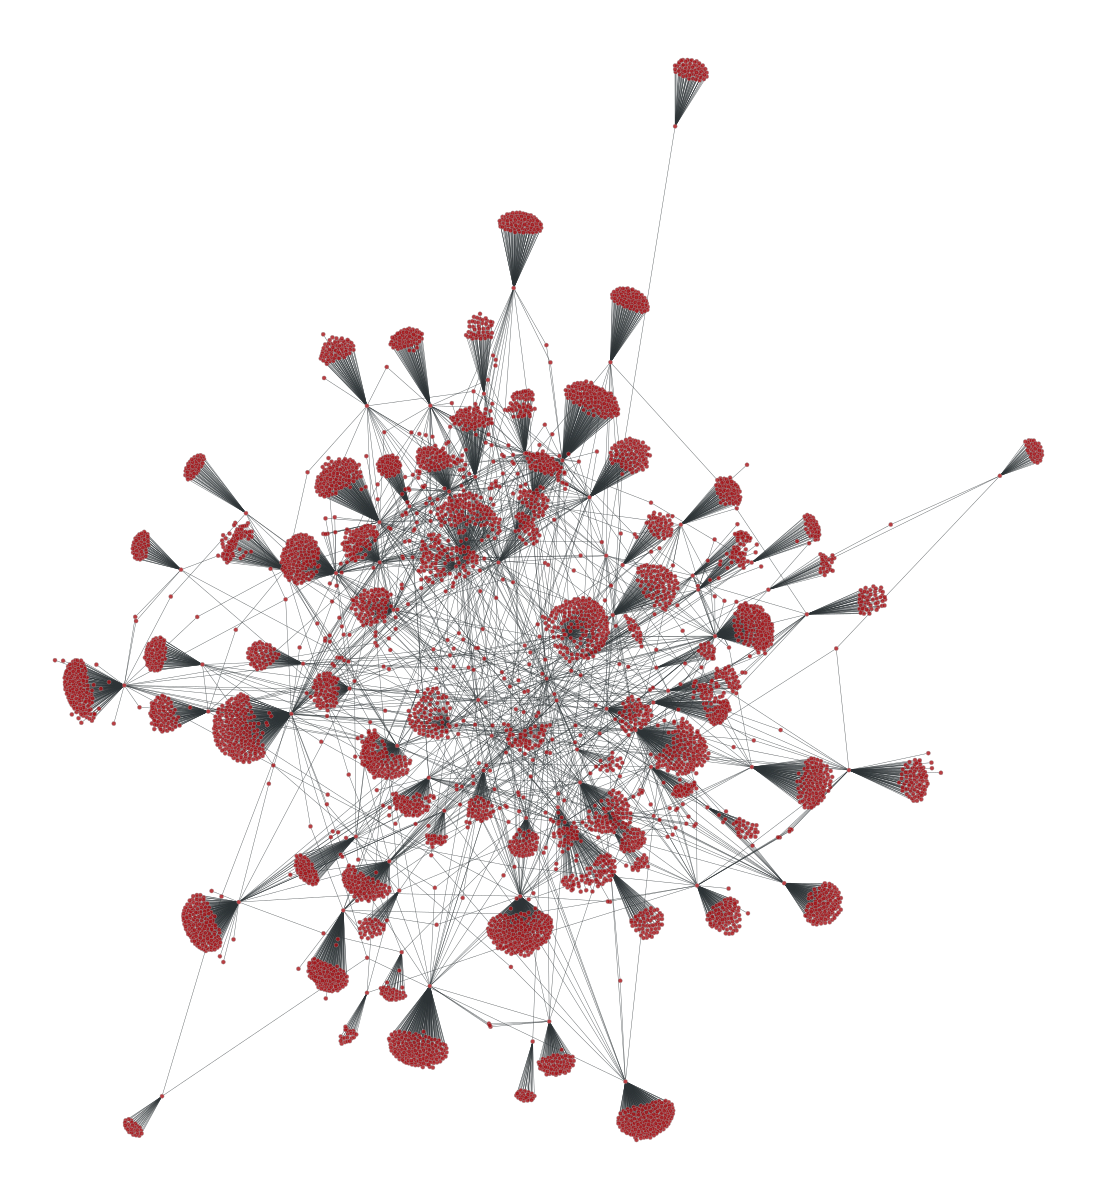

<VertexPropertyMap object with value type 'vector<double>', for Graph 0x127fd56a0, at 0x305a5e5d0>

In [10]:
from scipy.io import mmread

matrix = mmread("data/ia-reality/ia-reality.mtx")
graph_g = gt.Graph(matrix, directed=False)
pos = gt.fruchterman_reingold_layout(graph_g)
gt.graph_draw(graph_g, pos=pos)

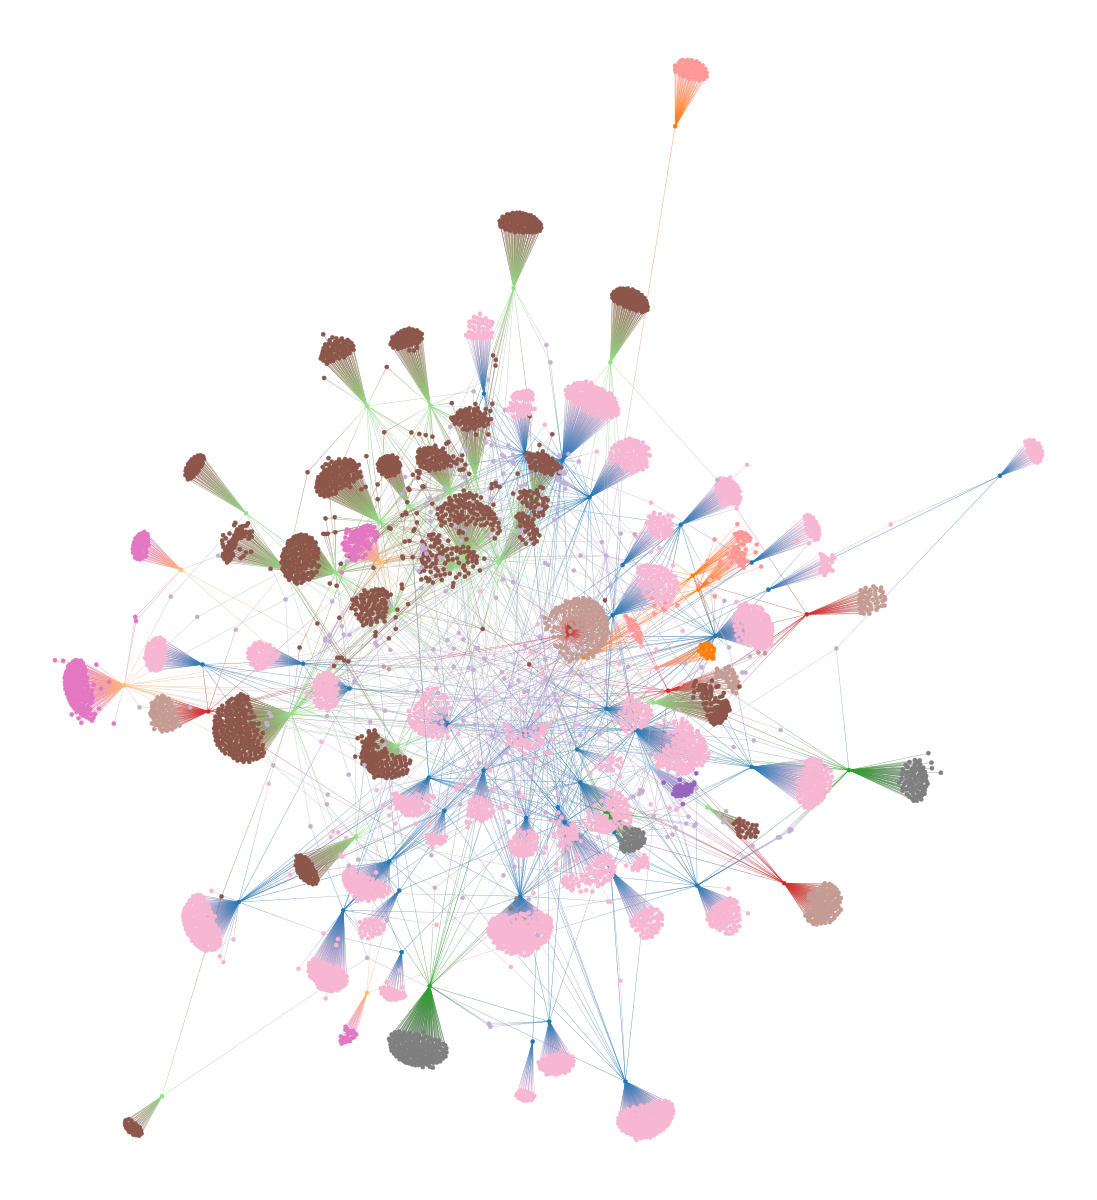

15 total communities.


In [12]:
import matplotlib.pyplot as plt

partitioned = gt.minimize_blockmodel_dl(graph_g)
partitioned.draw(pos=pos)
partitioned.draw(pos=pos, vertex_fill_color=partitioned.get_blocks(), output="images/graph_tool_phone_communities.png")

print(f"{partitioned.get_nonempty_B()} total communities.")  

In [19]:
# Create our dictionary 
blocks = partitioned.get_blocks()
gt_node_dict = {}
for index, item in enumerate(blocks):
    gt_node_dict[index] = item

print(gt_node_dict)
print(len(set(gt_node_dict.values())))

{0: 3, 1: 3, 2: 3, 3: 3, 4: 3, 5: 10, 6: 7, 7: 3, 8: 65, 9: 10, 10: 3, 11: 3, 12: 3, 13: 3, 14: 3, 15: 3, 16: 3, 17: 67, 18: 3, 19: 10, 20: 3, 21: 3, 22: 3, 23: 65, 24: 30, 25: 715, 26: 3, 27: 3, 28: 65, 29: 30, 30: 3, 31: 3, 32: 2965, 33: 65, 34: 65, 35: 2859, 36: 65, 37: 10, 38: 3, 39: 65, 40: 65, 41: 65, 42: 65, 43: 3, 44: 67, 45: 3, 46: 65, 47: 51, 48: 65, 49: 2965, 50: 51, 51: 65, 52: 3, 53: 3, 54: 65, 55: 2859, 56: 3, 57: 30, 58: 3, 59: 65, 60: 65, 61: 67, 62: 65, 63: 2965, 64: 65, 65: 3, 66: 67, 67: 65, 68: 3, 69: 65, 70: 67, 71: 30, 72: 65, 73: 3, 74: 3, 75: 6515, 76: 65, 77: 3, 78: 65, 79: 3, 80: 3, 81: 2859, 82: 3, 83: 3, 84: 65, 85: 3, 86: 3, 87: 6515, 88: 51, 89: 6515, 90: 6515, 91: 2859, 92: 2859, 93: 6515, 94: 6515, 95: 6515, 96: 6515, 97: 6515, 98: 6515, 99: 2859, 100: 6515, 101: 6515, 102: 6515, 103: 6515, 104: 6515, 105: 6515, 106: 6515, 107: 6515, 108: 6515, 109: 2965, 110: 6515, 111: 6515, 112: 6515, 113: 2859, 114: 6515, 115: 6515, 116: 6515, 117: 6515, 118: 6515, 1

#### Question 2c

/var/folders/3n/4c447n7j2yv7hw5yxxvb35880000gn/T/ipykernel_45856/123074976.py:4: DeprecationWarning: The default value for `spmatrix` is changing to `False` in v1.20.
             That means the default return type will be a sparse array.
             Unless you use * instead of @, ** for matrix power, or you depend
             on 2D shapes from e.g. `A.sum(axis=0)` it may not matter to you.
             See the spmatrix to sparray migration guide for details.
             https://docs.scipy.org/doc/scipy/reference/sparse.migration_to_sparray.html
             
  matrix = mmread("data/ia-reality/ia-reality.mtx")


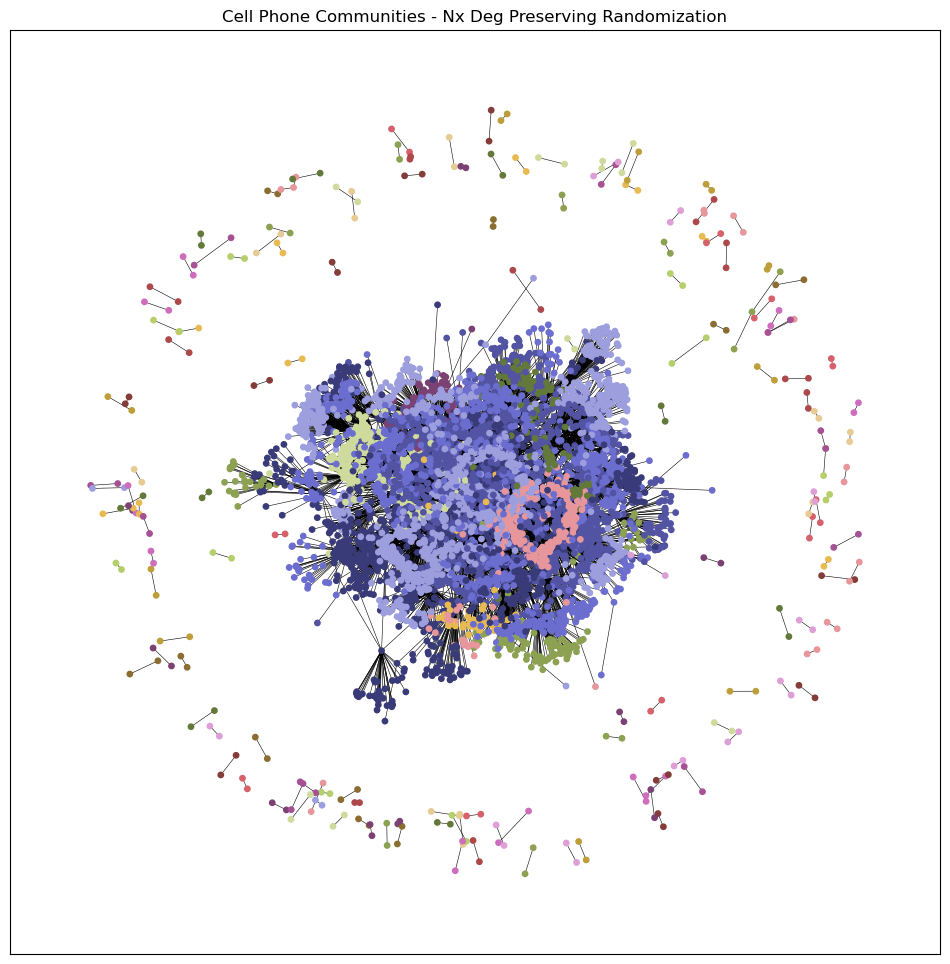

In [14]:
# NetworkX version
from scipy.io import mmread

matrix = mmread("data/ia-reality/ia-reality.mtx")
mit_call_network = nx.Graph(matrix)

nx_call_network_rand = nx.double_edge_swap(mit_call_network, nswap=500, max_tries=5000)

nx_communities_rand = nx.community.louvain_communities(nx_call_network_rand, seed=42)

nx_node_dict_rand = {
    node: community_id 
    for community_id, community_nodes in enumerate(nx_communities_rand) 
    for node in community_nodes
}

pos = nx.spring_layout(nx_call_network_rand)
colors_sns = plt.cm.tab20b(np.linspace(0,1,len(np.unique(list(nx_communities_rand)))))
colors_nodes = [colors_sns[nx_node_dict_rand[node]] for node in nx_call_network_rand.nodes()]

fig, ax = plt.subplots(1,1,figsize=(12,12),dpi=100)

nx.draw_networkx(nx_call_network_rand, pos=pos, node_color=colors_nodes, with_labels=False, ax=ax, node_size=15,width=0.4,)
plt.title("Cell Phone Communities - Nx Deg Preserving Randomization")

plt.savefig("images/nx_rand_cellphone_communities.png")

plt.show()

In [21]:
# Get the number of communities
print(f"Community count: {len(nx_communities_rand)}")

Community count: 201


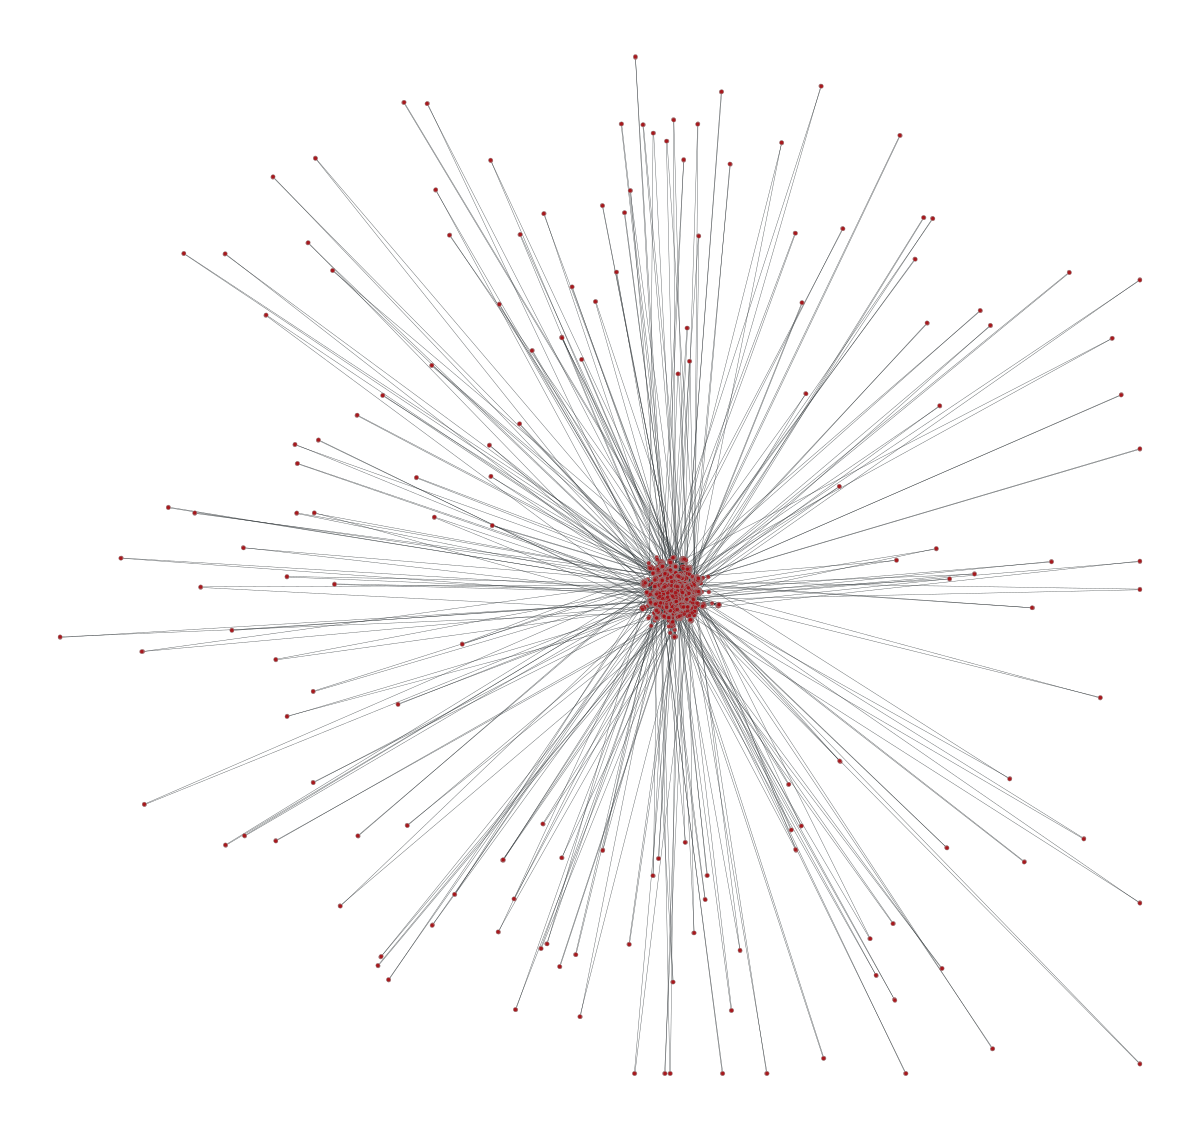

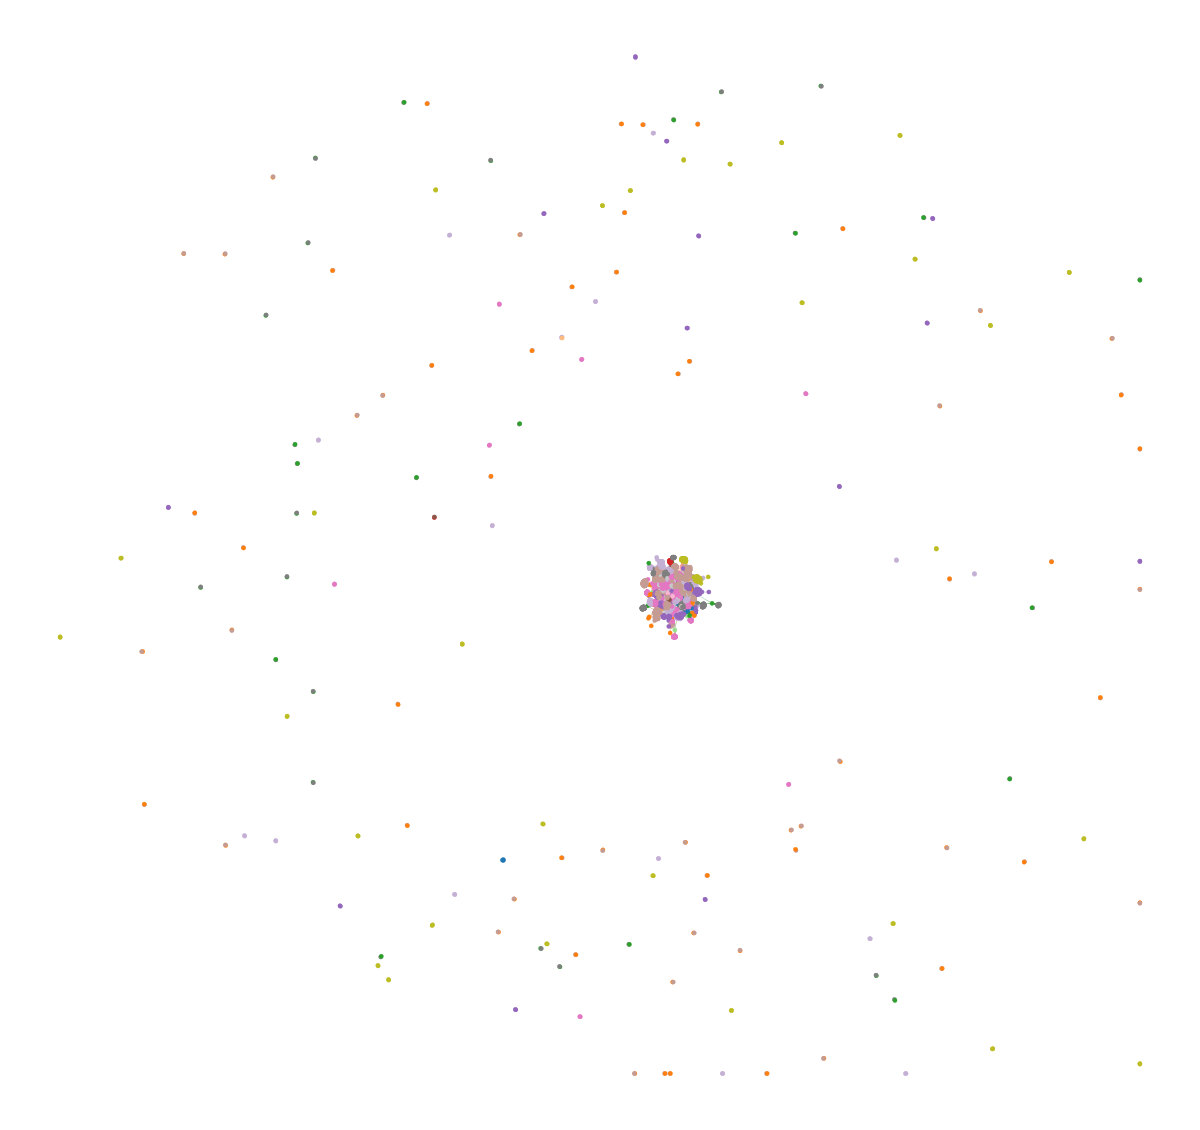

<VertexPropertyMap object with value type 'vector<double>', for Graph 0x1117c95b0, at 0x110e4e040>

In [15]:
# Graph Tool Version
import pyintergraph

# Create GT graph from networkX graph
gt_call_network_rand = pyintergraph.nx2gt(nx_call_network_rand, labelname="node_id")

pos = gt.fruchterman_reingold_layout(gt_call_network_rand)
gt.graph_draw(graph_g, pos=pos)
rand_state = gt.minimize_blockmodel_dl(gt_call_network_rand)
rand_state.draw(pos=pos)
rand_state.draw(pos=pos, vertex_fill_color=rand_state.get_blocks(), output="images/rand_gt_phone_communities.png")

In [18]:
print(f"{rand_state.get_nonempty_B()} total communities.")  

17 total communities.


In [20]:
# Create dictionary 
rand_blocks = rand_state.get_blocks()
print(len(rand_state.get_blocks()))
gt_node_dict_rand = {}
for index, item in enumerate(rand_blocks):
    gt_node_dict_rand[index] = item

print(gt_node_dict_rand)
print(len(set(gt_node_dict_rand.values())))

6809
{0: 77, 1: 34, 2: 34, 3: 77, 4: 47, 5: 10, 6: 47, 7: 34, 8: 34, 9: 10, 10: 77, 11: 65, 12: 34, 13: 47, 14: 15, 15: 15, 16: 77, 17: 34, 18: 34, 19: 10, 20: 2259, 21: 34, 22: 47, 23: 47, 24: 47, 25: 79, 26: 47, 27: 34, 28: 34, 29: 34, 30: 65, 31: 47, 32: 3285, 33: 34, 34: 77, 35: 5479, 36: 77, 37: 15, 38: 34, 39: 77, 40: 77, 41: 3611, 42: 77, 43: 34, 44: 47, 45: 15, 46: 47, 47: 34, 48: 77, 49: 3533, 50: 47, 51: 34, 52: 77, 53: 15, 54: 34, 55: 5479, 56: 15, 57: 77, 58: 34, 59: 77, 60: 77, 61: 65, 62: 65, 63: 3533, 64: 65, 65: 77, 66: 34, 67: 77, 68: 65, 69: 77, 70: 84, 71: 65, 72: 15, 73: 15, 74: 47, 75: 2161, 76: 77, 77: 65, 78: 79, 79: 34, 80: 34, 81: 5479, 82: 34, 83: 84, 84: 34, 85: 34, 86: 47, 87: 3285, 88: 47, 89: 3533, 90: 3533, 91: 3285, 92: 5479, 93: 3533, 94: 3533, 95: 3533, 96: 3533, 97: 3533, 98: 5479, 99: 5479, 100: 3285, 101: 3533, 102: 1706, 103: 3533, 104: 3533, 105: 3533, 106: 3533, 107: 3533, 108: 3533, 109: 3285, 110: 3533, 111: 3533, 112: 3533, 113: 5479, 114: 353

#### Question 2c

In [102]:
gt_node_dict

{0: 3,
 1: 3,
 2: 3,
 3: 3,
 4: 3,
 5: 10,
 6: 7,
 7: 3,
 8: 65,
 9: 10,
 10: 3,
 11: 3,
 12: 3,
 13: 3,
 14: 3,
 15: 3,
 16: 3,
 17: 67,
 18: 3,
 19: 10,
 20: 3,
 21: 3,
 22: 3,
 23: 65,
 24: 30,
 25: 715,
 26: 3,
 27: 3,
 28: 65,
 29: 30,
 30: 3,
 31: 3,
 32: 2965,
 33: 65,
 34: 65,
 35: 2859,
 36: 65,
 37: 10,
 38: 3,
 39: 65,
 40: 65,
 41: 65,
 42: 65,
 43: 3,
 44: 67,
 45: 3,
 46: 65,
 47: 51,
 48: 65,
 49: 2965,
 50: 51,
 51: 65,
 52: 3,
 53: 3,
 54: 65,
 55: 2859,
 56: 3,
 57: 30,
 58: 3,
 59: 65,
 60: 65,
 61: 67,
 62: 65,
 63: 2965,
 64: 65,
 65: 3,
 66: 67,
 67: 65,
 68: 3,
 69: 65,
 70: 67,
 71: 30,
 72: 65,
 73: 3,
 74: 3,
 75: 6515,
 76: 65,
 77: 3,
 78: 65,
 79: 3,
 80: 3,
 81: 2859,
 82: 3,
 83: 3,
 84: 65,
 85: 3,
 86: 3,
 87: 6515,
 88: 51,
 89: 6515,
 90: 6515,
 91: 2859,
 92: 2859,
 93: 6515,
 94: 6515,
 95: 6515,
 96: 6515,
 97: 6515,
 98: 6515,
 99: 2859,
 100: 6515,
 101: 6515,
 102: 6515,
 103: 6515,
 104: 6515,
 105: 6515,
 106: 6515,
 107: 6515,
 108: 6515,
 10

In [ ]:
from collections import Counter

cnt = Counter(gt_node_dict.values())

Counter({6515: 3140,
         2965: 2031,
         3963: 474,
         4770: 325,
         6808: 300,
         2859: 234,
         715: 159,
         786: 45,
         3: 39,
         10: 25,
         65: 24,
         67: 5,
         30: 4,
         51: 3,
         7: 1})

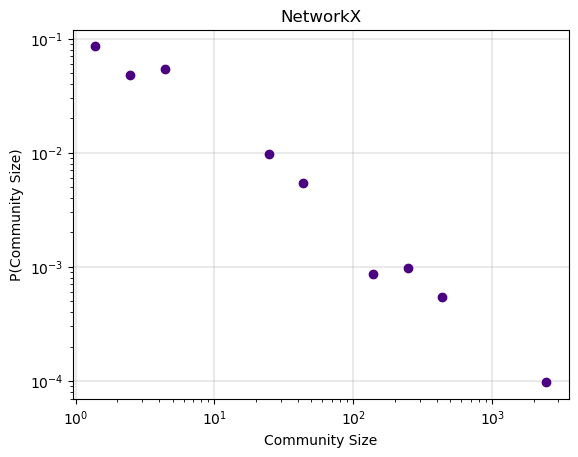

In [130]:
# Network X Original Graph
community_dist = list(cnt.values())
ordered = dict(cnt.most_common())

# get nice binned distributions 
deg_bins = np.logspace(0, np.log10(np.max(community_dist)+1), num=len(community_dist))
probs, _ = np.histogram(community_dist, bins=deg_bins, density=True)
final_bins = deg_bins[1:] - np.diff(deg_bins)/2.0

plt.loglog(final_bins, probs, marker='o',lw=0, c="indigo")
plt.ylabel(r"P(Community Size)", fontsize='medium')
plt.xlabel(r"Community Size", fontsize='medium')
plt.grid(linewidth=1.5, color='#999999', alpha=0.2, linestyle='-')    
plt.title(f'NetworkX', fontsize='large')   

plt.show()

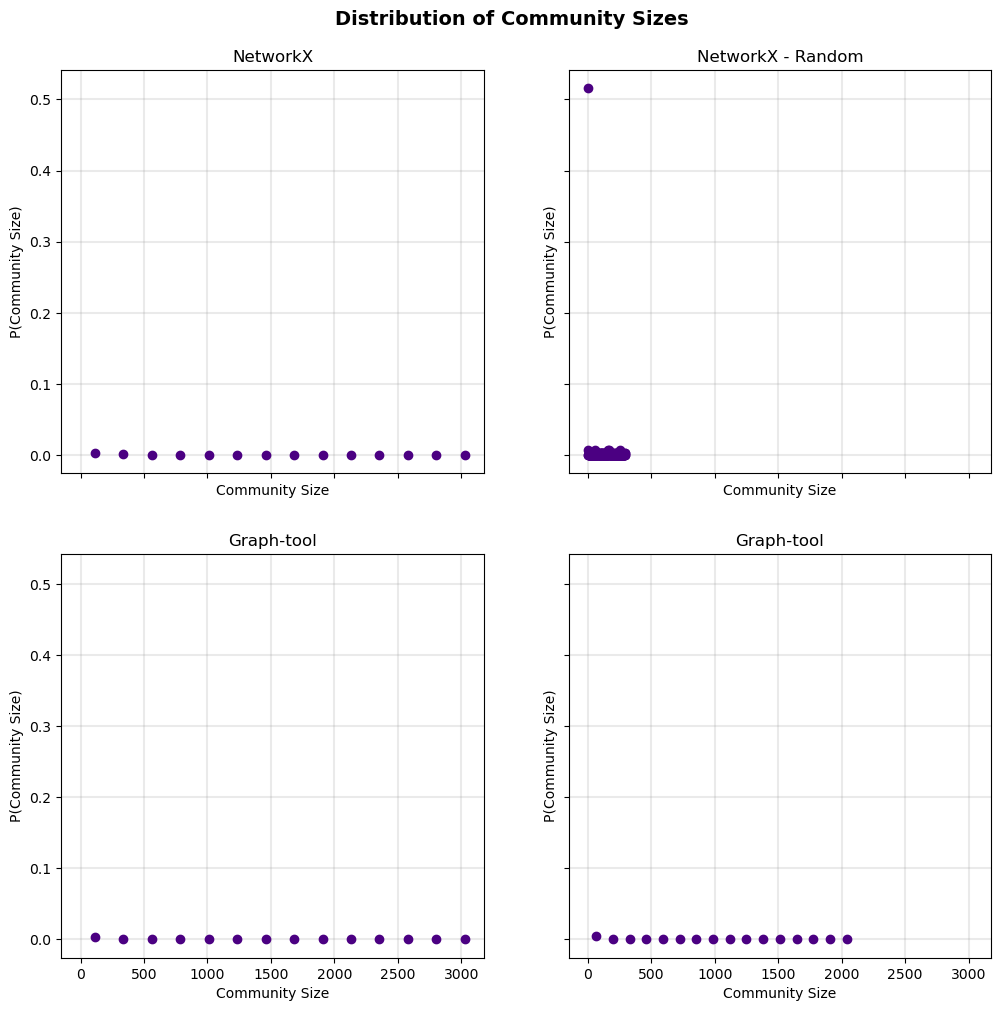

In [142]:
from collections import Counter

fig, ax = plt.subplots(2,2,figsize=(12,12),dpi=100, sharex=True, sharey=True,)

# Network X Original Graph
cnt = Counter(gt_node_dict.values())
community_dist = list(cnt.values())

# get nice binned distributions 
deg_bins = np.linspace(0, np.max(community_dist), num=len(community_dist))
probs, _ = np.histogram(community_dist, bins=deg_bins, density=True)
final_bins = deg_bins[1:] - np.diff(deg_bins)/2.0

ax[0,0].plot(final_bins, probs, marker='o',lw=0, c="indigo")
ax[0,0].set_ylabel(r"P(Community Size)", fontsize='medium')
ax[0,0].set_xlabel(r"Community Size", fontsize='medium')
ax[0,0].grid(linewidth=1.5, color='#999999', alpha=0.2, linestyle='-')    
ax[0,0].set_title(f'NetworkX', fontsize='large')  


# Network X Random Graph
cnt = Counter(nx_node_dict_rand.values())
community_dist = list(cnt.values())

# get nice binned distributions 
deg_bins = np.linspace(0, np.max(community_dist), num=len(community_dist))
probs, _ = np.histogram(community_dist, bins=deg_bins, density=True)
final_bins = deg_bins[1:] - np.diff(deg_bins)/2.0

ax[0,1].plot(final_bins, probs, marker='o',lw=0, c="indigo")
ax[0,1].set_ylabel(r"P(Community Size)", fontsize='medium')
ax[0,1].set_xlabel(r"Community Size", fontsize='medium')
ax[0,1].grid(linewidth=1.5, color='#999999', alpha=0.2, linestyle='-')    
ax[0,1].set_title(f'NetworkX - Random', fontsize='large')  

# Graph-tool Original Graph
cnt = Counter(gt_node_dict.values())
community_dist = list(cnt.values())

# get nice binned distributions 
deg_bins = np.linspace(0, np.max(community_dist), num=len(community_dist))
probs, _ = np.histogram(community_dist, bins=deg_bins, density=True)
final_bins = deg_bins[1:] - np.diff(deg_bins)/2.0

ax[1,0].plot(final_bins, probs, marker='o',lw=0, c="indigo")
ax[1,0].set_ylabel(r"P(Community Size)", fontsize='medium')
ax[1,0].set_xlabel(r"Community Size", fontsize='medium')
ax[1,0].grid(linewidth=1.5, color='#999999', alpha=0.2, linestyle='-')    
ax[1,0].set_title(f'Graph-tool', fontsize='large')  
  

# Graph-tool Random Graph
cnt = Counter(gt_node_dict_rand.values())
community_dist = list(cnt.values())

# get nice binned distributions 
deg_bins = np.linspace(0, np.max(community_dist), num=len(community_dist))
probs, _ = np.histogram(community_dist, bins=deg_bins, density=True)
final_bins = deg_bins[1:] - np.diff(deg_bins)/2.0

ax[1,1].plot(final_bins, probs, marker='o',lw=0, c="indigo")
ax[1,1].set_ylabel(r"P(Community Size)", fontsize='medium')
ax[1,1].set_xlabel(r"Community Size", fontsize='medium')
ax[1,1].grid(linewidth=1.5, color='#999999', alpha=0.2, linestyle='-')    
ax[1,1].set_title(f'Graph-tool', fontsize='large')  

fig.suptitle('Distribution of Community Sizes', fontsize=14, fontweight='bold', y=0.9)
plt.subplots_adjust(top=0.85) 


plt.savefig('images/community_dist_graphs_lin.png', bbox_inches='tight')
plt.show()

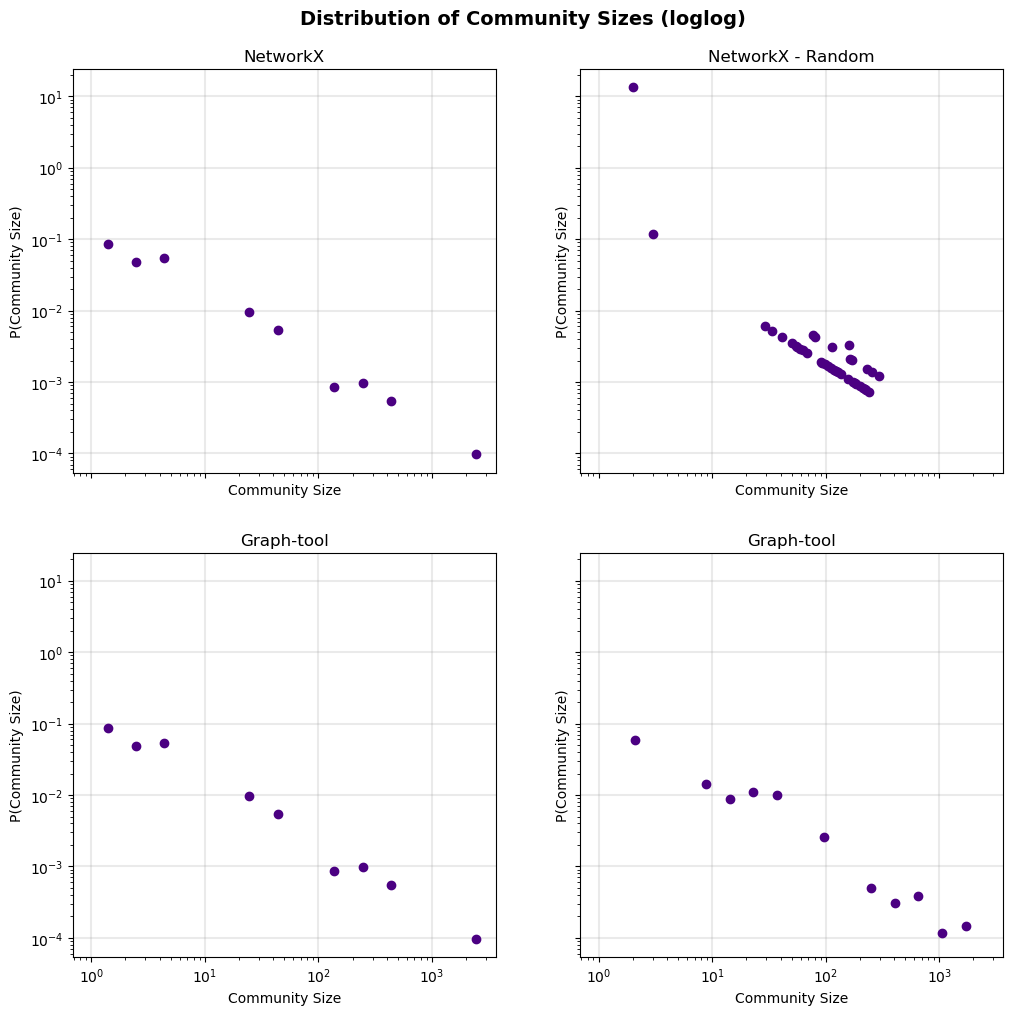

In [143]:
from collections import Counter

fig, ax = plt.subplots(2,2,figsize=(12,12),dpi=100, sharex=True, sharey=True,)

# Network X Original Graph
cnt = Counter(gt_node_dict.values())
community_dist = list(cnt.values())

# get nice binned distributions 
deg_bins = np.logspace(0, np.log10(np.max(community_dist)+1), num=len(community_dist))
probs, _ = np.histogram(community_dist, bins=deg_bins, density=True)
final_bins = deg_bins[1:] - np.diff(deg_bins)/2.0

ax[0,0].loglog(final_bins, probs, marker='o',lw=0, c="indigo")
ax[0,0].set_ylabel(r"P(Community Size)", fontsize='medium')
ax[0,0].set_xlabel(r"Community Size", fontsize='medium')
ax[0,0].grid(linewidth=1.5, color='#999999', alpha=0.2, linestyle='-')    
ax[0,0].set_title(f'NetworkX', fontsize='large')  


# Network X Random Graph
cnt = Counter(nx_node_dict_rand.values())
community_dist = list(cnt.values())

# get nice binned distributions 
deg_bins = np.logspace(0, np.log10(np.max(community_dist)+1), num=len(community_dist))
probs, _ = np.histogram(community_dist, bins=deg_bins, density=True)
final_bins = deg_bins[1:] - np.diff(deg_bins)/2.0

ax[0,1].loglog(final_bins, probs, marker='o',lw=0, c="indigo")
ax[0,1].set_ylabel(r"P(Community Size)", fontsize='medium')
ax[0,1].set_xlabel(r"Community Size", fontsize='medium')
ax[0,1].grid(linewidth=1.5, color='#999999', alpha=0.2, linestyle='-')    
ax[0,1].set_title(f'NetworkX - Random', fontsize='large')  

# Graph-tool Original Graph
cnt = Counter(gt_node_dict.values())
community_dist = list(cnt.values())

# get nice binned distributions 
deg_bins = np.logspace(0, np.log10(np.max(community_dist)+1), num=len(community_dist))
probs, _ = np.histogram(community_dist, bins=deg_bins, density=True)
final_bins = deg_bins[1:] - np.diff(deg_bins)/2.0

ax[1,0].loglog(final_bins, probs, marker='o',lw=0, c="indigo")
ax[1,0].set_ylabel(r"P(Community Size)", fontsize='medium')
ax[1,0].set_xlabel(r"Community Size", fontsize='medium')
ax[1,0].grid(linewidth=1.5, color='#999999', alpha=0.2, linestyle='-')    
ax[1,0].set_title(f'Graph-tool', fontsize='large')  
  

# Graph-tool Random Graph
cnt = Counter(gt_node_dict_rand.values())
community_dist = list(cnt.values())

# get nice binned distributions 
deg_bins = np.logspace(0, np.log10(np.max(community_dist)+1), num=len(community_dist))
probs, _ = np.histogram(community_dist, bins=deg_bins, density=True)
final_bins = deg_bins[1:] - np.diff(deg_bins)/2.0

ax[1,1].loglog(final_bins, probs, marker='o',lw=0, c="indigo")
ax[1,1].set_ylabel(r"P(Community Size)", fontsize='medium')
ax[1,1].set_xlabel(r"Community Size", fontsize='medium')
ax[1,1].grid(linewidth=1.5, color='#999999', alpha=0.2, linestyle='-')    
ax[1,1].set_title(f'Graph-tool', fontsize='large')  

fig.suptitle('Distribution of Community Sizes (loglog)', fontsize=14, fontweight='bold', y=0.9)
plt.subplots_adjust(top=0.85) 


plt.savefig('images/community_dist_graphs.png', bbox_inches='tight')
plt.show()

## Question 3

#### Question 3b

##### Question 3b i.

In [4]:
import random

def get_rand_num():
    """
    Helper function to return a random float that doesn't include 0

    @returns float between (0,1)
    """
    num = random.random()
    while num == 0:
        num = random.random()
    return num

In [5]:
import math
def get_power_law_seq(n, gamma, avg_deg):
    """
    This function creates a a sequence in a power-law distribution.

    @param n (int): The number of elements in the sequence
    @param gamma (float): The exponent of the powerlaw
    @param avg_deg (int): The average degree for the distribution

    @return a sequence of ints that form a power-law distribution
    """
    r_i = []
    # generate random numbers
    for i in range(0,n):
        rand = get_rand_num()
        r_i.append(rand)

    # Get k-min and k-max from average degree
    k_min = math.ceil(avg_deg * ((gamma-2)/(gamma-1)))
    k_max = math.ceil((k_min * n**(1/(gamma-1))))

    # Now get our probabilities for each possible degree,
    # based on the power-law distribution
    probs = []
    for k in range(k_min, k_max+1):
        # Get D(K)
        D_k = (k/k_min)**(-(gamma-1))
        probs.append(D_k)
        #print(f"K {k} is {D_k}")

    # Now use those probabilities to calculate degree count for each number
    final_degrees = []
    for r in r_i:
        for j,_ in enumerate(probs):
            # descend down the distribution until we are not smaller
            # than the next number 
            if j+1 >= len(probs) or r > probs[j+1]:
                final_degrees.append(j+k_min)
                break 
    final_degrees.sort()
    return final_degrees

In [391]:
final_degrees = get_power_law_seq(10000,2.5,3)

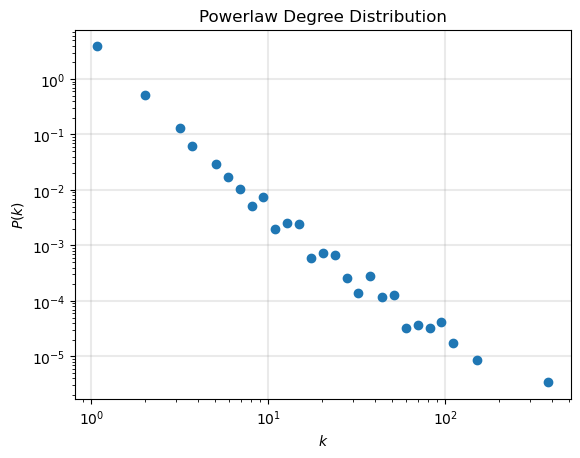

In [392]:
# get nice binned distributions 
deg_vals = final_degrees
deg_bins = np.logspace(0, np.log10(np.max(deg_vals)+1), num=40)
probs, _ = np.histogram(deg_vals, bins=deg_bins, density=True)
final_bins = deg_bins[1:] - np.diff(deg_bins)/2.0

# plot that puppy
plt.loglog(final_bins, probs, marker='o',lw=0)
plt.xlabel(r"$k$", fontsize='medium')
plt.ylabel(r"$P(k)$", fontsize='medium')
plt.grid(linewidth=1.5, color='#999999', alpha=0.2, linestyle='-')
plt.title(f'Powerlaw Degree Distribution', fontsize='large')

plt.savefig('images/deg_dist_graphs.pdf', bbox_inches='tight')
plt.show()

##### Question 3b ii.

In [6]:
def get_int_fraction(mu, degree):
    """
        This function gets the number of a node's degrees
        that connect to nodes in its own community.
    
        @param mu (float): The fraction of degrees external to a node's community
        @param gamma (degree): The number of degrees a node has
    
        @return (int) the number of degrees that must be internal
    """
    internal_degs = degree*(1-mu)
    num = random.random()

    # If between two degrees, we want the amount that
    # it returns either of the two degrees propotional
    # to the fraction
    if (num < internal_degs%round(internal_degs)):
        final_degs = round(internal_degs) + 1
    else:
        final_degs = round(internal_degs)
    return final_degs

In [390]:
# Usage of the function 
final_degrees = get_power_law_seq(10000,3,3)
mu = .4

internal_deg_list = []
for node, degree in enumerate(final_degrees):
    # get the number of internal degrees 
    int_degs = get_int_fraction(mu, degree)
    internal_deg_list.append(int_degs)

print(f"Max internal degrees: {max(internal_deg_list)}")
print(f"Max degrees: {max(final_degrees)}")

# looks right-ish

Max internal degrees: 114
Max degrees: 188


#### Question 3c

In [438]:
import time 

n_tracker = {}
gamma_tracker = {}
k_tracker = {}
mu_tracker = {}

for i_n in range(2,5):
    for i_gamma in range(0,10,2):
        for avg_degree in range(2,6):
            for i_mu in range(2,8,2):
                n = 10**i_n
                gamma = 2+i_gamma/10
                mu = i_mu / 10
                print(f"Testing with {n} nodes, gamma of {gamma}, mu of {mu} and average degree of {avg_degree}")
                start_time = time.perf_counter()
                try:
                    graph = nx.LFR_benchmark_graph(n, gamma, 1.5, mu=mu, average_degree=avg_degree)
                    end_time = time.perf_counter()
                    print(f"That ONE took {end_time - start_time} seconds to run. \n")
                    n_tracker[n] = n_tracker.get(n, 0) + 1
                    gamma_tracker[gamma] = gamma_tracker.get(gamma, 0) + 1
                    k_tracker[avg_degree] = k_tracker.get(avg_degree, 0) + 1
                    mu_tracker[mu] = mu_tracker.get(mu, 0) + 1
                except nx.ExceededMaxIterations:
                    print("Failed to converge, sad. \n")
                except Exception as e:
                    print(f"Other exception {e}")

            

Testing with 100 nodes, gamma of 2.0, mu of 0.2 and average degree of 2
Failed to converge, sad. 

Testing with 100 nodes, gamma of 2.0, mu of 0.4 and average degree of 2
Failed to converge, sad. 

Testing with 100 nodes, gamma of 2.0, mu of 0.6 and average degree of 2
Failed to converge, sad. 

Testing with 100 nodes, gamma of 2.0, mu of 0.2 and average degree of 3
Failed to converge, sad. 

Testing with 100 nodes, gamma of 2.0, mu of 0.4 and average degree of 3
Failed to converge, sad. 

Testing with 100 nodes, gamma of 2.0, mu of 0.6 and average degree of 3
Failed to converge, sad. 

Testing with 100 nodes, gamma of 2.0, mu of 0.2 and average degree of 4
Failed to converge, sad. 

Testing with 100 nodes, gamma of 2.0, mu of 0.4 and average degree of 4
Failed to converge, sad. 

Testing with 100 nodes, gamma of 2.0, mu of 0.6 and average degree of 4
That ONE took 0.0032856659963726997 seconds to run. 

Testing with 100 nodes, gamma of 2.0, mu of 0.2 and average degree of 5
Failed to 

In [ ]:
# Look closer at gamma
for i_gamma in range(0,10,2):
    for avg_degree in range(1,6,2):
        for i_mu in range(2,8,2):
            n = 10000
            gamma = 2+i_gamma/10
            mu = i_mu / 10
            print(f"Testing with {n} nodes, gamma of {gamma}, mu of {mu} and average degree of {avg_degree}")
            start_time = time.perf_counter()
            try:
                graph = nx.LFR_benchmark_graph(n, gamma, 1.5, mu=mu, average_degree=avg_degree)
                end_time = time.perf_counter()
                print(f"That one took {end_time - start_time} seconds to run. \n")
            except(nx.ExceededMaxIterations):
                print("Failed to converge. \n")

Testing with 10000 nodes, gamma of 2.0, mu of 0.2 and average degree of 1
Failed to converge. 

Testing with 10000 nodes, gamma of 2.0, mu of 0.4 and average degree of 1
Failed to converge. 

Testing with 10000 nodes, gamma of 2.0, mu of 0.6 and average degree of 1
Failed to converge. 

Testing with 10000 nodes, gamma of 2.0, mu of 0.2 and average degree of 3
Failed to converge. 

Testing with 10000 nodes, gamma of 2.0, mu of 0.4 and average degree of 3
Failed to converge. 

Testing with 10000 nodes, gamma of 2.0, mu of 0.6 and average degree of 3
Failed to converge. 

Testing with 10000 nodes, gamma of 2.0, mu of 0.2 and average degree of 5
Failed to converge. 

Testing with 10000 nodes, gamma of 2.0, mu of 0.4 and average degree of 5
Failed to converge. 

Testing with 10000 nodes, gamma of 2.0, mu of 0.6 and average degree of 5
Failed to converge. 

Testing with 10000 nodes, gamma of 2.2, mu of 0.2 and average degree of 1
Failed to converge. 

Testing with 10000 nodes, gamma of 2.2, 

In [402]:
# Look closer at average degree
for avg_degree in range(1,6):
    for i_mu in range(2,8,2):
        n = 10000
        gamma = 2.6
        mu = i_mu / 10
        print(f"Testing with {n} nodes, gamma of {gamma}, mu of {mu} and average degree of {avg_degree}")
        start_time = time.perf_counter()
        try:
            graph = nx.LFR_benchmark_graph(n, gamma, 1.5, mu=mu, average_degree=avg_degree)
            end_time = time.perf_counter()
            print(f"That one took {end_time - start_time} seconds to run. \n")
        except(nx.ExceededMaxIterations):
            print("Failed to converge. \n")

Testing with 10000 nodes, gamma of 2.6, mu of 0.2 and average degree of 1
Failed to converge. 

Testing with 10000 nodes, gamma of 2.6, mu of 0.4 and average degree of 1
Failed to converge. 

Testing with 10000 nodes, gamma of 2.6, mu of 0.6 and average degree of 1
Failed to converge. 

Testing with 10000 nodes, gamma of 2.6, mu of 0.2 and average degree of 2
Failed to converge. 

Testing with 10000 nodes, gamma of 2.6, mu of 0.4 and average degree of 2
Failed to converge. 

Testing with 10000 nodes, gamma of 2.6, mu of 0.6 and average degree of 2
That one took 0.6420895420014858 seconds to run. 

Testing with 10000 nodes, gamma of 2.6, mu of 0.2 and average degree of 3
Failed to converge. 

Testing with 10000 nodes, gamma of 2.6, mu of 0.4 and average degree of 3
Failed to converge. 

Testing with 10000 nodes, gamma of 2.6, mu of 0.6 and average degree of 3
That one took 0.5312994999112561 seconds to run. 

Testing with 10000 nodes, gamma of 2.6, mu of 0.2 and average degree of 4
Fail

In [439]:
n_tracker

{100: 21, 1000: 19, 10000: 17}

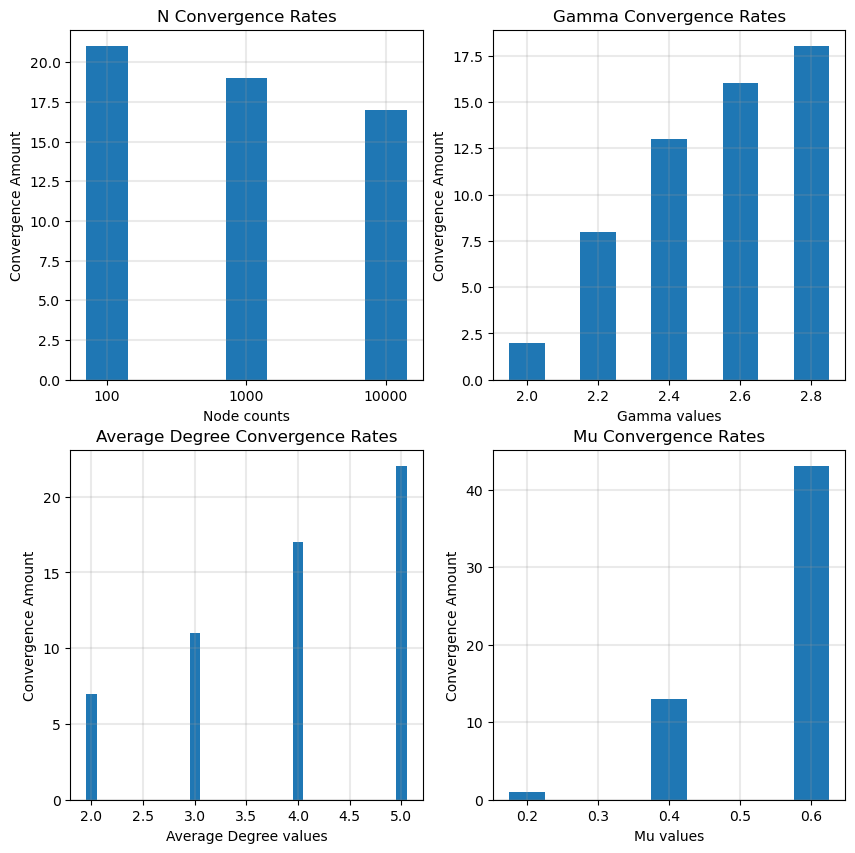

In [441]:
# Now look at the trackers

# n_tracker
# gamma_tracker
# k_tracker 
# mu_tracker 

fig, ax = plt.subplots(2,2,figsize=(10,10),dpi=100)

# N   
ax[0,0].bar([str(k) for k in n_tracker], list(n_tracker.values()), width=0.3)
ax[0,0].set_xlabel(r"Node counts", fontsize='medium')
ax[0,0].set_ylabel(r"Convergence Amount", fontsize='medium')
ax[0,0].set_title(f'N Convergence Rates', fontsize='large')
ax[0,0].grid(linewidth=1.5, color='#999999', alpha=0.2, linestyle='-')

# Gamma   
ax[0,1].bar(gamma_tracker.keys(), gamma_tracker.values(), width=0.1)
ax[0,1].set_xlabel(r"Gamma values", fontsize='medium')
ax[0,1].set_ylabel(r"Convergence Amount", fontsize='medium')
ax[0,1].set_title(f'Gamma Convergence Rates', fontsize='large')
ax[0,1].grid(linewidth=1.5, color='#999999', alpha=0.2, linestyle='-')

# Average Degree  
ax[1,0].bar(k_tracker.keys(), k_tracker.values(), width=0.1)
ax[1,0].set_xlabel(r"Average Degree values", fontsize='medium')
ax[1,0].set_ylabel(r"Convergence Amount", fontsize='medium')
ax[1,0].set_title(f'Average Degree Convergence Rates', fontsize='large')
ax[1,0].grid(linewidth=1.5, color='#999999', alpha=0.2, linestyle='-')

# Mu   
ax[1,1].bar(mu_tracker.keys(), mu_tracker.values(), width=0.05)
ax[1,1].set_xlabel(r"Mu values", fontsize='medium')
ax[1,1].set_ylabel(r"Convergence Amount", fontsize='medium')
ax[1,1].set_title(f'Mu Convergence Rates', fontsize='large')
ax[1,1].grid(linewidth=1.5, color='#999999', alpha=0.2, linestyle='-')



plt.savefig('images/model_convergence.png', bbox_inches='tight')
plt.show()

In [38]:
import math
def get_power_law_seq(n, gamma, avg_deg):
    """
    This function creates a a sequence in a power-law distribution.

    @param n (int): The number of elements in the sequence
    @param gamma (float): The exponent of the powerlaw
    @param avg_deg (int): The average degree for the distribution

    @return a sequence of ints that form a power-law distribution
    """
    r_i = []
    # generate random numbers
    for i in range(0,n):
        rand = get_rand_num()
        r_i.append(rand)

    # Get k-min and k-max from average degree
    k_min = math.ceil(avg_deg * ((gamma-2)/(gamma-1)))
    k_max = math.ceil((k_min * n**(1/(gamma-1))))

    # Now get our probabilities for each possible degree,
    # based on the power-law distribution
    probs = []
    for k in range(k_min, k_max+1):
        # Get D(K)
        D_k = (k/k_min)**(-(gamma-1))
        probs.append(D_k)
        #print(f"K {k} is {D_k}")

    # Now use those probabilities to calculate degree count for each number
    final_degrees = []
    for r in r_i:
        for j,_ in enumerate(probs):
            # descend down the distribution until we are not smaller
            # than the next number 
            if j+1 >= len(probs) or r > probs[j+1]:
                final_degrees.append(j+k_min)
                break

    # must return an even number for the configuration model
    if sum(final_degrees) % 2 == 1:
        final_degrees[random.randint(0, len(final_degrees)-1)] += 1
        
    final_degrees.sort()
    return final_degrees

#### Question 3b iv.

In [ ]:
def get_community_sizes(n, gamma, avg_deg, beta):
    """
    This function creates a sizes of communities in a power-law distribution.

    @param n (int): The number of nodes in the network
    @param gamma (float): The exponent of the powerlaw of the degree distribution
    @param avg_deg (int): The average degree for the degree distribution
    @param beta (float): The exponent of the powerlaw of the community size distribution

    @return a sequence of ints that form a power-law distribution of community sizes
    """
    # Get k-min and k-max for the network
    k_min = math.ceil(avg_deg * ((gamma-2)/(gamma-1)))
    k_max = math.ceil((k_min * n**(1/(gamma-1))))

    # Now get the community sizes min and max
    s_min = k_min + 1
    s_max = k_max + 1

    # Now get our probabilities for every possible degree
    probs = []
    for s in range(s_min, s_max+1):
        # Get D(s)
        D_s = (s/s_min)**(-(beta-1))
        probs.append(D_s)
        #print(f"S {s} is {D_s}")

    # now get vals until we have total
    size_vals = []
    count = 0
    while count < n:
        r = get_rand_num()
        # descend down the distribution till we find our number
        for j,_ in enumerate(probs):
            # descend down the distribution until we are not smaller
            # than the next number 
            if j+1 >= len(probs) or r > probs[j+1]:
                size_vals.append(j+s_min)
                count = count + j + s_min
                break
        # now get rid of the extra nodes we can't fit in the last community
    size_vals[-1] = size_vals[-1] - (count - n)
    size_vals.sort()
    return size_vals

In [113]:
# Implementation of the Entire Algorithm! 

N = 1000 # number of nodes
mu = .4
gamma = 2.5
beta = 1.5
avg_deg = 3
# get degree sequence 
final_degrees = get_power_law_seq(N,gamma,avg_deg)

# create network
G = nx.configuration_model(final_degrees)

for i in range(len(list(G.nodes()))):
    G.nodes[i]["degree"] = final_degrees[i]

    # get the node's internal degrees
    int_deg = get_int_fraction(mu, final_degrees[i])
    G.nodes[i]["int_deg"] = int_deg

    G.nodes[i]["homeless"] = True

# get our communities 
community_sizes = get_community_sizes(N, gamma, avg_deg, beta)

community_index = {i: [] for i in range(0,len(community_sizes))}

# everybody is homeless!
is_homeless = [True for _ in range(N)]

kill_me_count = 0
while True:
    if kill_me_count > 1000000:
        print("Alas, broken by the kill me count :( No convergence!")
        break
    # We done yet?
    if True not in is_homeless:
        break
    for node in G.nodes:
        # see if node has home
        if is_homeless[node]:
            random_community = random.randint(0, len(community_sizes)-1)
            if(community_sizes[random_community] > G.nodes[node]["int_deg"]):
                #print(f"Node {node} will be fit into community {random_community}")
                # is the community full? kick someone out
                if len(community_index[random_community]) >= community_sizes[random_community]:
                    # get random node in it
                    goneer = community_index[random_community][random.randint(0,len(community_index[random_community])-1)]
                    #print(f"But we are kicking out {community_index[random_community][goneer]} from community list {community_index[random_community]}")

                    # remove all forms of him
                    community_index[random_community].remove(goneer)
                    is_homeless[goneer] = True
                    G.nodes[goneer]["community"] = -1

                # now add the new guy 
                G.nodes[node]["community"] = random_community
                is_homeless[node] = False
                community_index[random_community].append(node)
    kill_me_count = kill_me_count + 1

# rewire all links
for node in G.nodes:
    internal_friends = []
    external_friends = []
    node_community = G.nodes[node]["community"]
    for edge in G.edges(node):
        friend = edge[1]
        if friend in community_index[node_community]:
            internal_friends.append(edge)
        else:
            external_friends.append(edge)
    friend_gap = G.nodes[node]["int_deg"] - len(internal_friends)
    for i in range(abs(friend_gap)):
        if friend_gap > 0 and len(external_friends) > 0:
            # we just do our best. if we don't have enough external friends, oh well
            # we want more internal friends!
            bye_friend = external_friends[random.randint(0, len(external_friends) - 1)]
            G.remove_edge(node, bye_friend[1])
            external_friends.remove(bye_friend)
            new_friend = community_index[node_community][random.randint(0, len(community_index[node_community]) - 2)] # minus two so we don't make friends with ourselves
            G.add_edge(node, new_friend)
        elif friend_gap < 0 and len(internal_friends) > 0:
            # too many internal friends :( 
            bye_friend = internal_friends[random.randint(0, len(internal_friends) - 1)]
            G.remove_edge(node, bye_friend[1])
            internal_friends.remove(bye_friend)
            new_friend = random.randint(0, N-1)
            while new_friend in community_index[node_community]:
                new_friend = random.randint(0, N-1)
            G.add_edge(node, new_friend)

                    

    
print(community_index)


{0: [420, 352], 1: [185, 409], 2: [160, 543], 3: [761, 133], 4: [235, 211], 5: [802, 12], 6: [427, 83, 312], 7: [604, 394, 395], 8: [134, 8, 120], 9: [535, 293, 145, 186], 10: [157, 459, 461, 273], 11: [531, 858, 95, 950, 545], 12: [796, 310, 557, 315, 151], 13: [826, 636, 561, 178, 764, 857], 14: [169, 343, 423, 98, 795, 820], 15: [794, 403, 689, 250, 144, 694, 269], 16: [122, 851, 669, 792, 890, 138, 718, 747], 17: [565, 915, 103, 462, 338, 222, 603, 257], 18: [744, 252, 365, 780, 586, 381, 509, 504, 947, 45], 19: [15, 756, 700, 264, 240, 515, 755, 520, 404, 481, 865], 20: [253, 911, 28, 415, 906, 332, 345, 372, 164, 399, 2, 621], 21: [939, 288, 707, 391, 883, 302, 900, 305, 838, 829, 308, 229], 22: [699, 978, 480, 279, 482, 600, 182, 205, 371, 785, 441, 866, 672], 23: [967, 976, 483, 614, 984, 560, 916, 226, 582, 704, 850, 42, 862, 158, 189, 625, 81, 443], 24: [37, 779, 735, 610, 797, 128, 475, 597, 514, 632, 725, 450, 491, 753, 232, 977, 555, 521, 303, 938], 25: [568, 174, 970, 503

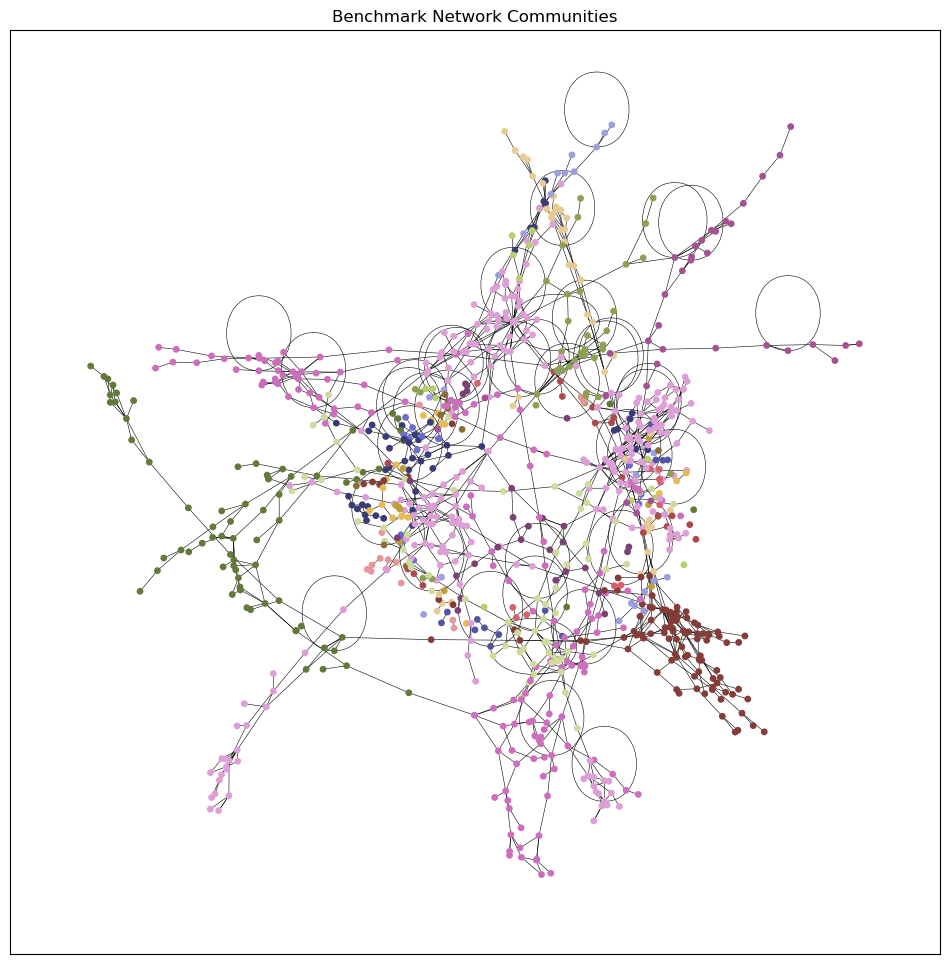

In [114]:
import numpy as np

# Now let's see how louvain communities do and visualize it

communities = nx.community.louvain_communities(G, seed=42)

nx_node_dict = {
    node: community_id 
    for community_id, community_nodes in enumerate(communities) 
    for node in community_nodes
}

pos = nx.spring_layout(G)
colors_sns = plt.cm.tab20b(np.linspace(0,1,len(np.unique(list(communities)))))
colors_nodes = [colors_sns[nx_node_dict[node]] for node in G.nodes()]

fig, ax = plt.subplots(1,1,figsize=(12,12),dpi=100)

nx.draw_networkx(G, pos=pos, node_color=colors_nodes, with_labels=False, ax=ax, node_size=15,width=0.4,)
plt.title("Benchmark Network Communities")

plt.show()

In [115]:
G.degree()

MultiDegreeView({0: 2, 1: 4, 2: 2, 3: 1, 4: 2, 5: 3, 6: 3, 7: 1, 8: 4, 9: 3, 10: 4, 11: 1, 12: 1, 13: 1, 14: 5, 15: 3, 16: 3, 17: 2, 18: 2, 19: 4, 20: 1, 21: 4, 22: 5, 23: 1, 24: 1, 25: 3, 26: 2, 27: 3, 28: 2, 29: 3, 30: 4, 31: 1, 32: 3, 33: 2, 34: 2, 35: 2, 36: 4, 37: 2, 38: 2, 39: 1, 40: 1, 41: 2, 42: 3, 43: 2, 44: 2, 45: 1, 46: 1, 47: 1, 48: 2, 49: 2, 50: 2, 51: 1, 52: 5, 53: 2, 54: 3, 55: 1, 56: 1, 57: 1, 58: 1, 59: 3, 60: 1, 61: 3, 62: 1, 63: 3, 64: 3, 65: 1, 66: 1, 67: 1, 68: 0, 69: 3, 70: 2, 71: 1, 72: 2, 73: 3, 74: 1, 75: 3, 76: 3, 77: 0, 78: 1, 79: 1, 80: 2, 81: 2, 82: 3, 83: 3, 84: 1, 85: 0, 86: 1, 87: 1, 88: 3, 89: 4, 90: 0, 91: 2, 92: 1, 93: 1, 94: 1, 95: 1, 96: 1, 97: 2, 98: 1, 99: 2, 100: 1, 101: 1, 102: 1, 103: 2, 104: 4, 105: 0, 106: 2, 107: 4, 108: 3, 109: 1, 110: 1, 111: 1, 112: 5, 113: 0, 114: 2, 115: 2, 116: 1, 117: 2, 118: 1, 119: 2, 120: 1, 121: 1, 122: 1, 123: 2, 124: 1, 125: 2, 126: 1, 127: 3, 128: 3, 129: 0, 130: 1, 131: 2, 132: 1, 133: 1, 134: 1, 135: 1, 136: 

[2, 4, 2, 1, 2, 3, 3, 1, 4, 3, 4, 1, 1, 1, 5, 3, 3, 2, 2, 4, 1, 4, 5, 1, 1, 3, 2, 3, 2, 3, 4, 1, 3, 2, 2, 2, 4, 2, 2, 1, 1, 2, 3, 2, 2, 1, 1, 1, 2, 2, 2, 1, 5, 2, 3, 1, 1, 1, 1, 3, 1, 3, 1, 3, 3, 1, 1, 1, 0, 3, 2, 1, 2, 3, 1, 3, 3, 0, 1, 1, 2, 2, 3, 3, 1, 0, 1, 1, 3, 4, 0, 2, 1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 1, 2, 4, 0, 2, 4, 3, 1, 1, 1, 5, 0, 2, 2, 1, 2, 1, 2, 1, 1, 1, 2, 1, 2, 1, 3, 3, 0, 1, 2, 1, 1, 1, 1, 0, 2, 3, 2, 4, 1, 4, 4, 1, 2, 1, 1, 1, 3, 1, 1, 3, 2, 1, 0, 2, 5, 5, 2, 3, 2, 2, 2, 1, 3, 0, 1, 2, 4, 2, 2, 2, 2, 4, 1, 3, 1, 2, 2, 0, 1, 3, 1, 2, 3, 1, 3, 1, 1, 2, 1, 2, 1, 2, 3, 2, 0, 2, 1, 2, 1, 2, 2, 3, 1, 1, 1, 3, 5, 2, 1, 1, 2, 2, 2, 1, 4, 1, 2, 1, 1, 3, 4, 2, 2, 4, 3, 1, 0, 3, 2, 1, 1, 2, 1, 3, 1, 2, 1, 1, 1, 2, 1, 4, 4, 4, 2, 3, 2, 0, 1, 2, 5, 3, 3, 1, 2, 2, 2, 1, 4, 1, 0, 2, 2, 1, 1, 2, 1, 1, 1, 1, 1, 1, 2, 1, 2, 1, 3, 1, 1, 1, 3, 1, 0, 2, 2, 2, 6, 2, 3, 2, 3, 4, 4, 2, 1, 2, 2, 1, 2, 2, 1, 1, 3, 1, 4, 2, 1, 1, 3, 1, 3, 1, 2, 1, 3, 1, 1, 1, 0, 2, 1, 1, 1, 2, 2, 1, 1, 2, 2, 3, 

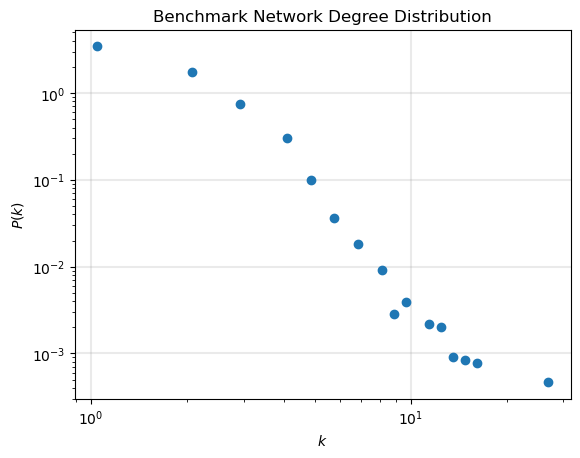

In [116]:
# And is it still a powerlaw?

# get nice binned distributions 
deg_vals = list(dict(G.degree()).values())
print(deg_vals)
deg_bins = np.logspace(0, np.log10(np.max(deg_vals)+1), num=40)
probs, _ = np.histogram(deg_vals, bins=deg_bins, density=True)
final_bins = deg_bins[1:] - np.diff(deg_bins)/2.0

# plot that puppy
plt.loglog(final_bins, probs, marker='o',lw=0)
plt.xlabel(r"$k$", fontsize='medium')
plt.ylabel(r"$P(k)$", fontsize='medium')
plt.grid(linewidth=1.5, color='#999999', alpha=0.2, linestyle='-')
plt.title(f'Benchmark Network Degree Distribution', fontsize='large')

plt.savefig('images/deg_dist_graphs.pdf', bbox_inches='tight')
plt.show()

## Question 4

The package can be installed with `pip install -i https://test.pypi.org/simple/ gilbert-nets==0.0.5`

In [3]:
from gilbert_nets import networkfx

networkfx.test_all()

Hello there! You've found my network functions.
All tests passed!
The following exception was properly thrown for random python object: Network must be NetworkX graph.
The following exception was properly thrown for nodeless graph: Network must have nodes.
Passed no-edge network test.
Passed one-edge network test.
Passed fully connected network test.
Passed multicomponent network test.
Passed complex network test.
Result is: True: All tests passed! Great job.
network estimated.
Calculating best minimal value for power law fit


Fitting xmin: 100%|██████████| 29/29 [00:00<00:00, 2247.38it/s]
/Users/caseygilbert/anaconda3/envs/graph-tool/lib/python3.14/site-packages/powerlaw/distributions.py:183: UserWarning: discrete=False but data exclusively contains integer values. Consider using discrete=True.
  warnings.warn('discrete=False but data exclusively contains integer values. Consider using discrete=True.')
/Users/caseygilbert/anaconda3/envs/graph-tool/lib/python3.14/site-packages/tailestim/estimators/tail_methods.py:193: RuntimeWarning: invalid value encountered in divide
  | (np.abs(1.0 - (M1**2) / M2) < 1e-10)
/Users/caseygilbert/anaconda3/envs/graph-tool/lib/python3.14/site-packages/tailestim/estimators/tail_methods.py:194: RuntimeWarning: invalid value encountered in divide
  | (np.abs(1.0 - (M1 * M2) / M3) < 1e-10)
/Users/caseygilbert/anaconda3/envs/graph-tool/lib/python3.14/site-packages/tailestim/estimators/tail_methods.py:193: RuntimeWarning: divide by zero encountered in divide
  | (np.abs(1.0 - (M1**2

Estimates: {'power': np.float64(2.9306498481598067), 'hill': np.float64(2.5957037183117064), 'moments': np.float64(3.097396717315872), 'kernel': np.float64(2.6738237811252983)}
Final degree: [2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 3, 4, 4, 4, 4, 4, 4, 4, 4, 4, 4, 5, 5, 5, 5, 8, 8, 9, 11]
